# Steering an LLM to vary its search algorithms: a de-commitment steering screen on Qwen3-8B

**Question.** Ask an LLM to "implement a path search" and it writes the same algorithm almost every time: BFS on a grid, Dijkstra on a weighted graph. Is that a *commitment* that can be loosened from the inside? This experiment pushes the model's residual stream toward a "list the possible approaches" state, instead of the "implement one" state, which we call de-commitment steering. It then asks whether the model writes a wider variety of **correct** algorithms, and compares this with simply prompting for variety.

| | |
|---|---|
| model | Qwen3-8B, thinking off; T = 1, top-p = 1, top-k off (Qwen3's 0.6 / 20 / 0.95 defaults overridden) |
| tasks (hidden tests) | **T1** grid path `solve(grid, start, goal)`; catalogue bfs, dfs, bidirectional_bfs, iddfs, astar, dijkstra_unit<br>**T2** weighted shortest path `solve(n, edges, s, t)`; catalogue dijkstra, bellman_ford_spfa, bidirectional_dijkstra, floyd_warshall, dial |
| direction | d_dc = mean h_R(LIST frames) − mean h_R(IMPLEMENT frames) at the read position R (the last prompt token), layer L* = 18 of 36, built from 50 + 50 held-out frame paraphrases |
| steering | x ← x + c·‖x‖·d̂ at R and at every generated token; c* = the largest c whose pass rate stays ≥ 0.8 × pass(c = 0), chosen on pass rate only |
| controls | HF c = 0 hook, vLLM baseline (N = 200), two random directions, a variable-name placebo direction, a breadth direction, cross-task transfer, the enumeration prompt, the modal ban and its mention control, a succession ban |
| outcome | hidden-test pass rate, and the Hill-1 number (exp of the Shannon entropy) of the algorithm labels of the *correct* programs; labels come from a runtime tracer plus AST rules, with an LLM judge on disagreements |

**What runs here.** `method.py` is the experiment's orchestrator: 17 stages, each a separate script. Its GPU stages (vLLM and Hugging Face generation with Qwen3-8B, about 2.1 GPU-hours on a 20 GB card) cannot run in a 10-minute CPU notebook. This notebook therefore does three things:

1. It defines `method.py` cell by cell and walks through its pipeline as a **dry run**, listing every command, log file and timeout.
2. It runs the CPU **`analyze` stage in-process** on all **1,770 labelled T2 samples** in `mini_demo_data.json`, with the original code of `analysis/stats.py`, `analysis/analyze.py`, `analysis/forecast.py` and `analysis/figures.py`. That recomputes the result tables, the pre-registered screen verdict and the figures.
3. It checks every recomputed number against the value the pipeline stored.

T2 is the task on which the arms differ. On T1 the model writes BFS in 100 % of the baseline, enumeration and steering samples, and only the ban prompts move it.

**Screen verdict: PARTIAL.** On T2, steering at c* = 0.25 moves the correct programs from Dijkstra to Bellman-Ford (rarefied Hill-1 +0.65, 90 % CI [0.31, 0.97]) at a 17-point pass-rate cost. A random direction of the same strength does almost the same, so the gain is not specific to the de-commitment direction.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the experiment's own pin from requirements.txt)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, statsmodels, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'statsmodels==0.14.6', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import argparse
import os
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# [notebook] imports of the analysis scripts that method.py's `analyze` stage runs; here they run in-process
import csv
import hashlib
import json
import math
import re
import types
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-1/experiment-4/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
if "metadata_samples" not in data["datasets"][0]["examples"][0]:
    # the URL can still serve an older copy of this file until the repository is updated: use the local one then
    print("GitHub copy lacks the per-sample records this notebook reads; using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
examples = data["datasets"][0]["examples"]
print(f"{data['datasets'][0]['dataset']}: {len(examples)} common-random-number slots, "
      f"{sum(len(v) for e in examples for v in e['metadata_samples'].values())} labelled samples, "
      f"{len(data['metadata']['conditions'])} arms")

GitHub copy lacks the per-sample records this notebook reads; using local mini_demo_data.json
T2_weighted_shortest_path: 100 common-random-number slots, 1770 labelled samples, 19 arms


## Configuration

**Data layout.** Each of the 100 examples is one *common-random-number slot*: a (baseline paraphrase, sample index) pair, 10 × 10. Every steering arm generated that slot with the same prompt and the same seed as the unsteered HF c = 0 sample.
* `output` is the c = 0 label.
* `predict_<arm>` is `label|pass` or `label|fail` under every other arm.
* `metadata_samples` holds the per-sample fields the analysis reads. The vLLM baseline has two samples per slot (N = 200).
* `metadata_code` holds the programs written under c = 0 and under d_dc at c*.

**Pipeline walk-through.** `RUN_STAGE_SCRIPTS` switches between a dry run (the default) and real execution of the stage scripts. Real execution only works when this notebook sits in the full artifact folder, next to its `.venv`, with Qwen3-8B in the Hugging Face cache and a 20 GB GPU.

**Analysis knobs.** The other parameters set the resampling sizes of the `analyze` stage, and the original value of each is noted beside it. With the original values and the original seeds, every recomputed number, intervals included, equals the stored one to floating-point precision. With smaller values, only the exact quantities match: pass rates, counts, plug-in Hill numbers, TV distances, flips and the dose-response fits.

In [5]:
# ---- pipeline walk-through (method.py) ----
RUN_STAGE_SCRIPTS = False  # True executes every stage script: needs the full artifact folder with its .venv,
                           # Qwen3-8B in the HF cache and a 20 GB GPU (about 2.1 GPU-hours); False = dry run
STAGES_ARGV = []           # method.py's command line; [] = all 17 stages (the default), e.g. ["--stages", "analyze"]

# ---- analyze stage (analysis/analyze.py, analysis/stats.py) ----
# The original values below run in about a minute on one CPU core (most of it in the buy table). For a
# quick look use NB, N_REP_POINT, N_REP_BOOT, N_MC = 200, 100, 10, 2000 (a few seconds); the exact quantities
# (pass rates, counts, plug-in Hill numbers, TV, flips, dose-response) do not depend on these sizes.
NB = 2000           # bootstrap resamples per 90% interval                      (original: 2000)
N_REP_POINT = 1000  # rarefaction repetitions of each rarefied point estimate   (original: 1000)
N_REP_BOOT = 30     # rarefaction repetitions inside each bootstrap replicate   (original: 30)
N_MC = 20000        # Monte-Carlo permutations of the engine check's chi^2 test  (original: 20000; a 2 x 2 table,
                    # as on T2, uses Fisher's exact test instead)

## Shared constants (`common.py`)

`method.py` starts with `from common import FORECAST_DIR, RAW_DIR, RESULTS_DIR, TASKS_DIR, setup_logger`. The constants that it and the analysis use are copied here from `common.py`, together with the task specifications and the algorithm catalogues, for reference. Two things change for the notebook:

* paths hang off the working directory, because a notebook has no `__file__`;
* `TASKS` is narrowed to T2, the only task in the demo data.

In [6]:
# ---- from common.py ----
WS = Path.cwd()  # [notebook] the script uses Path(__file__).resolve().parent
TASKS_DIR = WS / "tasks"
LABELLER_DIR = WS / "labeller"
PROMPTS_DIR = WS / "prompts"
DATA_DIR = WS / "data"
RAW_DIR = DATA_DIR / "raw"
CACHE_DIR = WS / "cache"
LABEL_CACHE = CACHE_DIR / "labels"
DIRECTIONS_DIR = WS / "directions"
FORECAST_DIR = WS / "forecast"
GOLD_DIR = WS / "gold"
RESULTS_DIR = WS / "results"
FIGURES_DIR = WS / "figures"
LOGS_DIR = WS / "logs"

MODEL_ID = "Qwen/Qwen3-8B"
N_LAYERS = 36
LAYERS = list(range(8, 29))          # candidate read/steer layers (hidden_states index), below 0.8 L
GRID_C = [0.25, 0.5, 1.0, 1.5]        # steering coefficient grid (c = 0 is the zero-strength control)

TASKS = ["T2"]  # [notebook] the original runs ["T1", "T2"]; the demo data holds the T2 samples only

SPEC = {
    "T1": (
        "Task: write a Python function solve(grid, start, goal). grid is a list of equal-length strings in which . "
        "is an open cell and # is a wall; start and goal are (row, col) tuples of open cells. A move goes up, down, "
        "left or right to an open cell inside the grid. Return any valid path from start to goal as a list of "
        "(row, col) tuples that begins with start, ends with goal and in which consecutive cells are adjacent; "
        "return [] if goal cannot be reached. Grids have at most 30 rows and 30 columns. Use only the Python "
        "standard library. Return only one ```python code block containing solve."
    ),
    "T2": (
        "Task: write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100); "
        "edges is a list of (u, v, w) tuples with integer weights 0 <= w <= 100; parallel edges, self-loops and "
        "cycles may occur. Return the length of a shortest path from s to t as an int, or -1 if t is unreachable "
        "from s (0 when s == t). Use only the Python standard library. Return only one ```python code block "
        "containing solve."
    ),
}

# Catalogue modes per task (label ids) and the display names used inside ban / mention prompts.
CATALOGUE = {
    "T1": ["bfs", "dfs", "bidirectional_bfs", "iddfs", "astar", "dijkstra_unit"],
    "T2": ["dijkstra", "bellman_ford_spfa", "bidirectional_dijkstra", "floyd_warshall", "dial"],
}
DISPLAY = {
    "T1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bidirectional_bfs": "bidirectional BFS",
        "iddfs": "iterative-deepening DFS",
        "astar": "A* search",
        "dijkstra_unit": "Dijkstra's algorithm",
    },
    "T2": {
        "dijkstra": "Dijkstra's algorithm",
        "bellman_ford_spfa": "the Bellman-Ford algorithm (including SPFA)",
        "bidirectional_dijkstra": "bidirectional Dijkstra",
        "floyd_warshall": "the Floyd-Warshall algorithm",
        "dial": "Dial's algorithm (bucket queue)",
    },
}
DEFINITIONS = {
    "T1": {
        "bfs": "breadth-first search with a FIFO queue (deque or list.pop(0)), recursive or iterative",
        "dfs": "depth-first search with a LIFO stack or plain recursion, no outer depth-limit loop",
        "bidirectional_bfs": "two simultaneous breadth-first frontiers, one from start and one from goal, that meet",
        "iddfs": "iterative deepening: repeated depth-limited DFS from start with an increasing depth limit",
        "astar": "best-first search on a heap keyed by g+h or h with h = Manhattan distance to goal (A* or greedy best-first)",
        "dijkstra_unit": "uniform-cost search / Dijkstra on a heap keyed by path length g only (no heuristic)",
    },
    "T2": {
        "dijkstra": "Dijkstra's algorithm with one priority queue (heap), nodes popped in non-decreasing distance",
        "bellman_ford_spfa": "Bellman-Ford edge relaxation in repeated passes, or SPFA (FIFO queue with re-enqueueing)",
        "bidirectional_dijkstra": "two Dijkstra searches, forward from s and backward from t on reversed edges, that meet",
        "floyd_warshall": "all-pairs Floyd-Warshall triple loop dist[i][j] = min(dist[i][j], dist[i][k] + dist[k][j])",
        "dial": "Dial's algorithm: Dijkstra with an array of buckets indexed by distance instead of a heap",
    },
}


def setup_logger(name: str, level: str = "INFO") -> None:
    LOGS_DIR.mkdir(parents=True, exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def cond_name_steer(direction: str, coef: float, layer: int) -> str:
    return f"steer:{direction}:c={coef:g}:L={layer}"

## `method.py` 1/5: the stage list

The whole experiment is one ordered list of stages. `label` appears four times because labelling runs after every generation wave. Each GPU stage runs in its own process, so vLLM and HF are never loaded together.

| stage | script(s) | what it does | engine |
|---|---|---|---|
| `meta` | `analysis/record_meta.py` | hardware, protocol and deviation records | – |
| `prompts` | `prompts/make_paraphrases.py` | all instruction sets: baseline 20, enumerate 10, ban 10, mention 20, listall 10, 5 direction frames × 50 | – |
| `tasks` | `tasks/build_tests.py` | hidden tests (43 for T1, 39 for T2) and their time limits. **R0 gate:** the 12 references pass and the 6 deliberately wrong programs fail | – |
| `states` | `gpu/hf_states.py` | residual states h_R at the read position for 930 prompts → `cache/hR_*.npy` | HF |
| `directions` | `analysis/directions.py` | d_dc and the control directions for layers 8–28, the layer choice L* = 18, the commitment test | – |
| `vllm1` | `gpu/vllm_gen.py --session s1` | baseline (N = 200) and enumeration prompt (N = 100) per task | vLLM |
| `label` | `labeller/daemon.py --once`, `labeller/judge.py --bulk` | hidden tests, runtime tracer and AST rules; an LLM judge on disagreements | – |
| `steer` | `gpu/hf_steer.py` (with the labelling daemon) | steering hook, c grid, c* and bisection, rand1/rand2, placebo, breadth, cross-task transfer | HF |
| `gate` | `labeller/gate.py` | labeller gate against an adjudicated gold set | – |
| `commit` | `analysis/forecast.py modal`, `commit-ban` | the modal algorithm X; sha256-committed forecasts of the ban outcome | – |
| `vllm2` | `gpu/vllm_gen.py --session s2 --with-mention` | ban:X and mention:X prompts (N = 100 each) | vLLM |
| `succ` | `analysis/forecast.py commit-succ` | committed forecasts for the second ban (X and its successor) | – |
| `vllm3` | `gpu/vllm_gen.py --session s3` | succession ban (N = 100) | vLLM |
| `analyze` | `record_meta`, `forecast verify`, `analyze`, `figures`, `method_out` | every result table, the screen verdict, the figures and `method_out.json` | – |

In [7]:
# method.py: WS = Path(__file__).resolve().parent; sys.path.insert(0, str(WS)); from common import ... (cell above)
PY = str(WS / ".venv" / "bin" / "python")
STAGES = ["meta", "prompts", "tasks", "states", "directions", "vllm1", "label", "steer", "label", "gate", "commit",
          "vllm2", "label", "succ", "vllm3", "label", "analyze"]
DRY_RUN_PLAN: list[dict] = []  # [notebook] the commands a dry run would have executed, in order

## `method.py` 2/5: `gpu_env()`

This is the environment of every stage process. It reads the Hugging Face hub offline, keeps the vLLM, Triton and inductor caches inside the workspace, and makes vLLM spawn its workers rather than fork them.

In [8]:
def gpu_env() -> dict:
    e = dict(os.environ)
    e.update({"HF_HUB_OFFLINE": "1", "TOKENIZERS_PARALLELISM": "false",
              "PYTORCH_CUDA_ALLOC_CONF": "expandable_segments:True",
              "VLLM_CACHE_ROOT": str(WS / ".engine_cache/vllm"), "TRITON_CACHE_DIR": str(WS / ".engine_cache/triton"),
              "TORCHINDUCTOR_CACHE_DIR": str(WS / ".engine_cache/inductor"), "XDG_CACHE_HOME": str(WS / ".engine_cache/xdg"),
              "VLLM_WORKER_MULTIPROC_METHOD": "spawn", "PYTHONUNBUFFERED": "1"})
    return e

## `method.py` 3/5: `run()`, one stage command

`run()` executes a script with the workspace's interpreter and appends its output to `logs/<name>`. It also enforces a timeout and raises on a non-zero exit code. The only notebook change is the dry-run branch: it logs and records the command instead of executing it.

In [9]:
def run(args: list[str], log: str, timeout_s: float) -> None:
    t0 = time.time()
    logger.info(f"RUN {' '.join(args)}  (log: logs/{log})")
    if not RUN_STAGE_SCRIPTS:  # [notebook] dry run: the stage scripts, Qwen3-8B and the GPU are not available here
        DRY_RUN_PLAN.append({"command": " ".join(args), "log": f"logs/{log}", "timeout_h": timeout_s / 3600})
        return
    with (WS / "logs" / log).open("a") as fh:
        p = subprocess.run([PY, *args], cwd=WS, env=gpu_env(), stdout=fh, stderr=subprocess.STDOUT, timeout=timeout_s)
    if p.returncode != 0:
        raise RuntimeError(f"stage command failed (rc={p.returncode}): {' '.join(args)}; see logs/{log}")
    logger.info(f"done in {(time.time() - t0) / 60:.1f} min")

## `method.py` 4/5: `stage()`, the dispatcher

`stage()` maps each stage name to one or more commands. Most stages skip work whose output is already on disk, so re-running `method.py` resumes an interrupted run.

The steering stage also starts the labelling daemon. It has to run alongside, because `gpu/hf_steer.py` waits for test labels before it can pick c* on pass rate. In the dry run the daemon is listed but not started; this is the second notebook change.

In [10]:
def stage(name: str) -> None:
    if name == "meta":
        run(["analysis/record_meta.py"], "record_meta.out", 300)
    elif name == "prompts":
        if not (WS / "prompts" / "paraphrases.json").exists():
            run(["prompts/make_paraphrases.py"], "prompts.out", 300)
    elif name == "tasks":
        reuse = ["--reuse-limits"] if (TASKS_DIR / "tests_T1.json").exists() else []
        run(["tasks/build_tests.py", *reuse], "build_tests.out", 3600)
    elif name == "states":
        if not (WS / "cache" / "hR_index.json").exists():
            run(["gpu/hf_states.py"], "hf_states.out", 3600)
    elif name == "directions":
        if not (RESULTS_DIR / "layer_selection.json").exists():
            run(["analysis/directions.py"], "directions.out", 3600)
        elif not (RESULTS_DIR / "commitment_test.json").exists():
            run(["analysis/directions.py", "--commitment-only"], "commitment.out", 3600)
    elif name == "vllm1":
        run(["gpu/vllm_gen.py", "--session", "s1"], "vllm_s1.out", 4 * 3600)
    elif name == "steer":
        if not (RESULTS_DIR / "steer_state.json").exists() or "finished_utc" not in (RESULTS_DIR / "steer_state.json").read_text():
            # the steering process waits for test labels when it needs c*; run the daemon alongside it
            if not RUN_STAGE_SCRIPTS:  # [notebook] dry run: list the background daemon instead of starting it
                logger.info("POPEN labeller/daemon.py in the background, alongside hf_steer.py  (log: logs/daemon.out)")
                return run(["gpu/hf_steer.py", "--budget-min", "125"], "hf_steer.out", 4 * 3600)
            d = subprocess.Popen([PY, "labeller/daemon.py"], cwd=WS, env=gpu_env(),
                                 stdout=(WS / "logs" / "daemon.out").open("a"), stderr=subprocess.STDOUT)
            try:
                run(["gpu/hf_steer.py", "--budget-min", "125"], "hf_steer.out", 4 * 3600)
            finally:
                (WS / "logs" / "daemon.stop").touch()
                d.wait(timeout=600)
                (WS / "logs" / "daemon.stop").unlink(missing_ok=True)
    elif name == "label":
        run(["labeller/daemon.py", "--once"], "daemon.out", 4 * 3600)
        run(["labeller/judge.py", "--bulk", "--cap", "0.80"], "judge.out", 1800)
    elif name == "gate":
        run(["labeller/gate.py"], "gate.out", 1800)
    elif name == "commit":
        if not (FORECAST_DIR / "commit_log.jsonl").exists():
            run(["analysis/forecast.py", "modal"], "forecast.out", 600)
            run(["analysis/forecast.py", "commit-ban"], "forecast.out", 600)
    elif name == "vllm2":
        run(["gpu/vllm_gen.py", "--session", "s2", "--with-mention"], "vllm_s2.out", 4 * 3600)
    elif name == "succ":
        if not (RESULTS_DIR / "succession_plan.json").exists():
            run(["analysis/forecast.py", "commit-succ"], "forecast.out", 600)
    elif name == "vllm3":
        run(["gpu/vllm_gen.py", "--session", "s3"], "vllm_s3.out", 4 * 3600)
    elif name == "analyze":
        run(["analysis/record_meta.py"], "record_meta.out", 300)
        run(["analysis/forecast.py", "verify"], "forecast.out", 300)
        run(["analysis/analyze.py"], "analyze.out", 3600)
        run(["analysis/figures.py"], "figures.out", 1200)
        run(["analysis/method_out.py"], "method_out.out", 1200)
    else:
        raise ValueError(name)

## `method.py` 5/5: `main()`

`main()` parses `--stages` and runs the stages in order. Jupyter has no command line, so its arguments come from `STAGES_ARGV` in the config cell.

In [11]:
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stages", default=",".join(STAGES), help="comma-separated subset, in order")
    a = ap.parse_args(STAGES_ARGV)  # [notebook] arguments from the config cell instead of sys.argv
    setup_logger("method")
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    for s in a.stages.split(","):
        logger.info(f"=== stage {s} ===")
        stage(s.strip())
    logger.info("pipeline complete: see method_out.json, results/ and figures/")

## Walk through the pipeline (dry run)

With `RUN_STAGE_SCRIPTS = False`, every `run()` call is logged and recorded instead of executed, so the table below lists the full pipeline's commands in the order it runs them.

Measured wall times on one RTX A4500 (20 GB) with 11 CPUs:

| stage | wall time |
|---|---|
| `states` | 1.6 min |
| `vllm1` | 28 min, of which 12.7 min went to a failed compiled start |
| `steer` | 78.6 min |
| `vllm2` | 8.7 min |
| `vllm3` | 5.9 min |
| `analyze` (CPU) | 6 min |

The LLM judge cost $0.06.

In [12]:
DRY_RUN_PLAN.clear()
main()
pd.DataFrame(DRY_RUN_PLAN)

10:56:50|INFO   |=== stage meta ===


10:56:50|INFO   |RUN analysis/record_meta.py  (log: logs/record_meta.out)


10:56:50|INFO   |=== stage prompts ===


10:56:50|INFO   |RUN prompts/make_paraphrases.py  (log: logs/prompts.out)


10:56:50|INFO   |=== stage tasks ===


...

10:56:51|INFO   |RUN analysis/analyze.py  (log: logs/analyze.out)


10:56:51|INFO   |RUN analysis/figures.py  (log: logs/figures.out)


10:56:51|INFO   |RUN analysis/method_out.py  (log: logs/method_out.out)


10:56:51|INFO   |pipeline complete: see method_out.json, results/ and figures/


,command,log,timeout_h
0,analysis/record_meta.py,logs/record_meta.out,0.083333
1,prompts/make_paraphrases.py,logs/prompts.out,0.083333
2,tasks/build_tests.py,logs/build_tests.out,1.000000
3,gpu/hf_states.py,logs/hf_states.out,1.000000
4,analysis/directions.py,logs/directions.out,1.000000
5,gpu/vllm_gen.py --session s1,logs/vllm_s1.out,4.000000
6,labeller/daemon.py --once,logs/daemon.out,4.000000
7,labeller/judge.py --bulk --cap 0.80,logs/judge.out,0.500000
8,gpu/hf_steer.py --budget-min 125,logs/hf_steer.out,4.000000
9,labeller/daemon.py --once,logs/daemon.out,4.000000


## The `analyze` stage, in-process

In the full pipeline, `stage("analyze")` runs five scripts on the samples stored on disk. Here they run in-process, on their original code, against the 1,770 T2 samples of `mini_demo_data.json`:

* `analysis/forecast.py verify` re-hashes the committed forecasts;
* `analysis/analyze.py` assembles the samples and computes every result table and the screen verdict;
* `analysis/figures.py` draws the figures;
* `analysis/method_out.py` writes the per-slot output file. Here its slot loop becomes a consistency check of the loaded data;
* `analysis/record_meta.py` only re-records the protocol, so it is not repeated (its output is `data["metadata"]["protocol"]`).

### `analysis/stats.py`

This is the statistics toolkit:

* Wilson intervals.
* Hill numbers. Hill-q = (Σ p_i^q)^(1/(1−q)), so Hill-1 = exp(Shannon entropy) is the effective number of algorithms.
* Rarefied Hill-1: the mean Hill-1 of random subsamples of a common size m. It makes arms with different numbers of correct programs comparable.
* TV and JS distances.
* Bootstraps that resample paraphrases first and then samples within them. They are paired when two arms share paraphrases and seeds.
* Flip rates under common random numbers.
* Exact tests.
* A logistic dose-response with paraphrase-clustered standard errors.

`analyze.py` imports this module as `S`; the namespace at the end of the cell keeps that call syntax.

In [13]:
# ---- analysis/stats.py ----
def wilson(k: int, n: int, z: float = 1.959964) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return [max(0.0, c - h), min(1.0, c + h)]


def hill(labels, q: float) -> float:
    c = np.array(list(Counter(labels).values()), dtype=float)
    if c.sum() == 0:
        return float("nan")
    p = c / c.sum()
    if q == 0:
        return float((p > 0).sum())
    if q == 1:
        return float(np.exp(-(p * np.log(p)).sum()))
    return float((p ** q).sum() ** (1 / (1 - q)))


def rarefied_hill1(labels, m: int, n_rep: int = 1000, seed: int = 0) -> float:
    labels = list(labels)
    n = len(labels)
    if n == 0 or m <= 0:
        return float("nan")
    if m >= n:
        return hill(labels, 1)
    codes = {x: i for i, x in enumerate(sorted(set(labels)))}
    y = np.array([codes[x] for x in labels])
    rng = np.random.default_rng(seed)
    vals = np.empty(n_rep)
    for r in range(n_rep):
        sub = y[rng.permutation(n)[:m]]
        c = np.bincount(sub).astype(float)
        c = c[c > 0] / m
        vals[r] = np.exp(-(c * np.log(c)).sum())
    return float(vals.mean())


def dist(labels) -> dict:
    c = Counter(labels)
    n = sum(c.values())
    return {k: v / n for k, v in c.items()} if n else {}


def tv(p: dict, q: dict) -> float:
    keys = set(p) | set(q)
    return 0.5 * sum(abs(p.get(k, 0.0) - q.get(k, 0.0)) for k in keys)


def js(p: dict, q: dict, keys: list[str], pseudo: float = 0.5, counts_q: dict | None = None) -> float:
    """Jensen-Shannon divergence (nats) between forecast p and realised counts (add-0.5 smoothed)."""
    P = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    P = P / P.sum()
    if counts_q is not None:
        Q = np.array([counts_q.get(k, 0) + pseudo for k in keys], dtype=float)
    else:
        Q = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    Q = Q / Q.sum()
    M = 0.5 * (P + Q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log(a[mask] / b[mask])).sum())
    return 0.5 * kl(P, M) + 0.5 * kl(Q, M)


def correct_labels(rows: list[dict]) -> list[str]:
    return [r["label"] for r in rows if r["passed"]]


def boot_stat(rows: list[dict], stat, n_boot: int = 2000, seed: int = 0, cluster: bool = True) -> list[float]:
    """90% bootstrap interval of stat(rows); cluster=True resamples paraphrases, then samples within them."""
    rng = np.random.default_rng(seed)
    by = {}
    for r in rows:
        by.setdefault(r["paraphrase_id"], []).append(r)
    keys = sorted(by)
    vals = []
    for _ in range(n_boot):
        if cluster:
            pick = [keys[i] for i in rng.integers(0, len(keys), len(keys))]
            res = []
            for k in pick:
                g = by[k]
                res.extend(g[i] for i in rng.integers(0, len(g), len(g)))
        else:
            res = [rows[i] for i in rng.integers(0, len(rows), len(rows))]
        v = stat(res)
        if v == v:
            vals.append(v)
    if not vals:
        return [float("nan"), float("nan")]
    return [float(np.percentile(vals, 5)), float(np.percentile(vals, 95))]


def boot_diff(rows_a: list[dict], rows_b: list[dict], stat, n_boot: int = 2000, seed: int = 0, cluster: bool = True,
              paired: bool = True) -> dict:
    """90% interval of stat(a) - stat(b). Cluster mode resamples paraphrase ids jointly (paired) or separately."""
    rng = np.random.default_rng(seed)

    def group(rows):
        by = {}
        for r in rows:
            by.setdefault(r["paraphrase_id"], []).append(r)
        return by
    A, B = group(rows_a), group(rows_b)
    ka, kb = sorted(A), sorted(B)
    common = sorted(set(ka) & set(kb))
    vals = []
    for _ in range(n_boot):
        if cluster:
            if paired and common:
                pick = [common[i] for i in rng.integers(0, len(common), len(common))]
                pa = pb = pick
            else:
                pa = [ka[i] for i in rng.integers(0, len(ka), len(ka))]
                pb = [kb[i] for i in rng.integers(0, len(kb), len(kb))]
            ra, rb = [], []
            for k in pa:
                g = A[k]
                ra.extend(g[i] for i in rng.integers(0, len(g), len(g)))
            for k in pb:
                g = B[k]
                rb.extend(g[i] for i in rng.integers(0, len(g), len(g)))
        else:
            ra = [rows_a[i] for i in rng.integers(0, len(rows_a), len(rows_a))]
            rb = [rows_b[i] for i in rng.integers(0, len(rows_b), len(rows_b))]
        va, vb = stat(ra), stat(rb)
        if va == va and vb == vb:
            vals.append(va - vb)
    if not vals:
        return {"ci90": [float("nan"), float("nan")], "n_boot": 0}
    return {"ci90": [float(np.percentile(vals, 5)), float(np.percentile(vals, 95))], "n_boot": len(vals),
            "p_le_0": float(np.mean(np.array(vals) <= 0))}


def hill1_cc(rows: list[dict]) -> float:
    lab = correct_labels(rows)
    return hill(lab, 1) if lab else float("nan")


def make_rarefied(m: int, n_rep: int = 30, seed: int = 0):
    def f(rows):
        lab = correct_labels(rows)
        if len(lab) < m:
            return float("nan")
        return rarefied_hill1(lab, m, n_rep=n_rep, seed=seed)
    return f


def pass_rate(rows: list[dict]) -> float:
    return float(np.mean([r["passed"] for r in rows])) if rows else float("nan")


def flips(rows: list[dict], ref_rows: list[dict], ref_mode: str) -> dict:
    ref = {(r["paraphrase_id"], r["sample_id"]): r for r in ref_rows}
    n = fl = away = into_nc = 0
    for r in rows:
        k = (r["paraphrase_id"], r["sample_id"])
        if k not in ref:
            continue
        n += 1
        a, b = ref[k]["label"], r["label"]
        if a != b:
            fl += 1
            if a == ref_mode:
                away += 1
            if b == "no_code":
                into_nc += 1
    return {"n_matched": n, "flip_rate": fl / n if n else float("nan"),
            "flip_away_from_mode_rate": away / n if n else float("nan"),
            "flip_into_no_code_rate": into_nc / n if n else float("nan"),
            "flip_ci95": wilson(fl, n)}


def fisher_or_mc(table: np.ndarray, n_mc: int = 20000, seed: int = 0) -> dict:
    """Exact test for a 2 x K table: Fisher for 2x2, otherwise a Monte-Carlo permutation test of chi^2."""
    from scipy.stats import fisher_exact
    table = np.asarray(table, dtype=int)
    table = table[:, table.sum(0) > 0]
    if table.shape[1] <= 1:
        return {"test": "degenerate", "p": 1.0}
    if table.shape == (2, 2):
        return {"test": "fisher_exact", "p": float(fisher_exact(table)[1])}
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(table.shape[1]), table.sum(0))
    n0 = int(table[0].sum())

    def chi2(t):
        e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
        return float(((t - e) ** 2 / np.where(e > 0, e, 1)).sum())
    obs = chi2(table)
    cnt = 0
    for _ in range(n_mc):
        perm = rng.permutation(labels)
        a = np.bincount(perm[:n0], minlength=table.shape[1])
        b = np.bincount(perm[n0:], minlength=table.shape[1])
        if chi2(np.vstack([a, b])) >= obs - 1e-12:
            cnt += 1
    return {"test": "monte_carlo_chi2", "p": (cnt + 1) / (n_mc + 1), "chi2": obs}


def logit_cluster(x: np.ndarray, y: np.ndarray, groups: np.ndarray) -> dict:
    import statsmodels.api as sm
    if len(set(y.tolist())) < 2:
        return {"slope": None, "se": None, "p": None, "note": "outcome constant"}
    X = sm.add_constant(x.astype(float))
    try:
        m = sm.GLM(y.astype(float), X, family=sm.families.Binomial()).fit(cov_type="cluster",
                                                                          cov_kwds={"groups": groups})
        return {"intercept": float(m.params[0]), "slope": float(m.params[1]), "se": float(m.bse[1]),
                "p": float(m.pvalues[1]), "ci95": [float(v) for v in m.conf_int()[1]]}
    except (ValueError, np.linalg.LinAlgError) as e:
        return {"slope": None, "se": None, "p": None, "note": f"fit failed: {e!r}"[:200]}


def cohen_kappa(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    return float((po - pe) / (1 - pe)) if pe < 1 else 1.0


def kappa_ci(a: list[str], b: list[str], n_boot: int = 2000, seed: int = 0) -> list[float]:
    rng = np.random.default_rng(seed)
    n = len(a)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        v = cohen_kappa([a[i] for i in idx], [b[i] for i in idx])
        if v == v:
            vals.append(v)
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))] if vals else [float("nan")] * 2


def self_test() -> None:
    assert abs(hill(list("abcd"), 1) - 4) < 1e-9 and abs(hill(list("aaaa"), 1) - 1) < 1e-9
    assert abs(hill(list("abcd"), 2) - 4) < 1e-9
    skew = list("a" * 90 + "b" * 7 + "c" * 2 + "d")
    assert rarefied_hill1(skew, 20, n_rep=500) <= hill(skew, 1) + 1e-9
    a = boot_stat([{"paraphrase_id": i % 10, "sample_id": i, "label": "x" if i % 3 else "y", "passed": True}
                   for i in range(100)], hill1_cc, n_boot=200, seed=1)
    b = boot_stat([{"paraphrase_id": i % 10, "sample_id": i, "label": "x" if i % 3 else "y", "passed": True}
                   for i in range(100)], hill1_cc, n_boot=200, seed=1)
    assert a == b
    assert math.isfinite(math.log(0.02))


# [notebook] analyze.py does `from analysis import stats as S`; the same functions, under the same name
S = types.SimpleNamespace(wilson=wilson, hill=hill, rarefied_hill1=rarefied_hill1, dist=dist, tv=tv, js=js,
                          correct_labels=correct_labels, boot_stat=boot_stat, boot_diff=boot_diff, hill1_cc=hill1_cc,
                          make_rarefied=make_rarefied, pass_rate=pass_rate, flips=flips, fisher_or_mc=fisher_or_mc,
                          logit_cluster=logit_cluster, cohen_kappa=cohen_kappa, kappa_ci=kappa_ci, self_test=self_test)
self_test()
print("stats self-test ok")

stats self-test ok


### Hash-committed forecasts (`analysis/forecast.py`)

The `commit` stage reads the modal algorithm X off the vLLM baseline. Before any ban sample existed, it then forecast what a "do not use X" prompt would produce:

* `dc`, the de-committed forecast, is the label distribution of the steered arm at c*, restricted to the surviving algorithms.
* Its rivals are the baseline frequencies (`freq_vllm`, `freq_hf`) and a `uniform` forecast.
* Every forecast is mixed with a floor: q(s) = 0.98 · (0.95 · p(s) + 0.05 / |S|), and q(other) = 0.02.

Each forecast file went into a commit log together with its sha256. `cmd_verify()` re-hashes the stored forecast objects and compares the hashes.

In [14]:
# ---- analysis/forecast.py ----
def modal(rows: list[dict], exclude: set[str] | None = None) -> dict:
    exclude = exclude or set()
    c = Counter(r["label"] for r in rows if r["passed"] and r["label"] not in exclude)
    n = sum(c.values())
    if n == 0:
        return {"X": None, "flag": "no_correct_samples", "counts": {}}
    top = c.most_common(2)
    lead = (top[0][1] - (top[1][1] if len(top) > 1 else 0)) / n * 100
    return {"X": top[0][0], "lead_points": lead, "flag": None if lead >= 15 else "no_clear_mode", "counts": dict(c),
            "n_correct": n}


def mix(p: dict, S: list[str]) -> dict:
    q = {s: 0.98 * (0.95 * p.get(s, 0.0) + 0.05 / len(S)) for s in S}
    q["other"] = 0.02
    return q


def freq_forecast(rows: list[dict], S: list[str]) -> dict:
    c = Counter(r["label"] for r in rows if r["passed"] and r["label"] in S)
    tot = sum(c.values()) + 0.5 * len(S)
    return mix({s: (c.get(s, 0) + 0.5) / tot for s in S}, S)


def dc_forecast(rows: list[dict], S: list[str]) -> tuple[dict, str | None]:
    c = Counter(r["label"] for r in rows if r["passed"] and r["label"] in S)
    tot = sum(c.values())
    if tot == 0:
        return mix({s: 1 / len(S) for s in S}, S), "degenerate"
    return mix({s: c.get(s, 0) / tot for s in S}, S), None


def sha_of(obj: dict) -> str:
    return hashlib.sha256(json.dumps(obj, sort_keys=True, separators=(",", ":")).encode()).hexdigest()


def steer_rows(task: str, layer: int, c: float, direction: str = "dc") -> list[dict]:
    # [notebook] the original reads labelled(task, f"hf_{task}_steer-{direction}-c{c:g}-L{layer}.jsonl"); the same
    # rows are the assembled samples of that condition (`by` is built in the assemble cell below)
    return by.get((task, cond_name_steer(direction, c, layer)), [])


def forecasts_for(task: str, S: list[str], cst: dict, layer: int) -> tuple[dict, dict]:
    cstar = cst[task]["c_star"]
    fc, flags = {}, {}
    fc["dc"], flags["dc"] = dc_forecast(steer_rows(task, layer, cstar), S)
    fc["freq_vllm"] = freq_forecast(by.get((task, "baseline"), []), S)  # [notebook] labelled(task, "vllm_<t>_baseline.jsonl")
    fc["freq_hf"] = freq_forecast(steer_rows(task, layer, 0.0), S)
    fc["uniform"] = mix({s: 1 / len(S) for s in S}, S)
    for c in sorted(float(k) for k in cst[task]["pass_rates"]):
        if c in (0.0, cstar):
            continue
        rows = steer_rows(task, layer, c)
        if rows:
            fc[f"dc_c={c:g}"], flags[f"dc_c={c:g}"] = dc_forecast(rows, S)
    return fc, flags


def cmd_verify() -> dict:
    out = {}
    for rec in data["metadata"]["forecast"]["commit_log"]:  # [notebook] read_jsonl(FORECAST_DIR / "commit_log.jsonl")
        obj = data["metadata"]["forecast"]["files"][rec["file"]]  # [notebook] json.loads((FORECAST_DIR / rec["file"]).read_text())
        out[rec["file"]] = {"stored": rec["sha256"], "recomputed": sha_of(obj), "ok": sha_of(obj) == rec["sha256"]}
    (RESULTS_DIR / "forecast_verify.json").write_text(json.dumps(out, indent=1))
    logger.info(f"verify: {out}")
    return out


# stage analyze, step 2: analysis/forecast.py verify
setup_logger("forecast")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)  # [notebook] this folder already exists in the artifact
verify = cmd_verify()

10:56:51|INFO   |verify: {'predict_T2_ban1.json': {'stored': '4fc8e0f3dd4758327a1b722f47d0ad375f11f19b9739907a05ed9e8291f034f0', 'recomputed': '4fc8e0f3dd4758327a1b722f47d0ad375f11f19b9739907a05ed9e8291f034f0', 'ok': True}, 'predict_T2_succ2.json': {'stored': '4f7d413e4497db9750c615aa837230151b41f50ce045c9b717e56dc1878ee382', 'recomputed': '4f7d413e4497db9750c615aa837230151b41f50ce045c9b717e56dc1878ee382', 'ok': True}}


### Assemble the samples (`analyze.assemble`) and start `analyze.main()`

The original `assemble()` walks `data/raw/*.jsonl` and looks up every generated text in the content-addressed label cache. Here the same per-sample fields come from `data`: every slot carries one record per arm, and two for the vLLM baseline. Compliance with the ban prompts is derived exactly as in the original.

`analyze.main()` then loads the modal algorithm X, c* and the pre-registration, and groups the samples by (task, condition).

In [15]:
# ---- analysis/analyze.py ----
def assemble() -> list[dict]:
    # [notebook] the original reads data/raw/*.jsonl + the label cache and rewrites data/samples.jsonl; here the same
    # per-sample fields come from `data`, one record per arm and slot (two for the vLLM baseline)
    succ = data["metadata"]["succession_plan"]  # results/succession_plan.json
    out = []
    for ex in data["datasets"][0]["examples"]:
        for cond, labs in ex["metadata_samples"].items():
            for lab in labs:
                r = {"task": ex["metadata_task"], "paraphrase_id": ex["metadata_paraphrase_id"]}
                comp = None
                if cond.startswith("ban:"):
                    comp = bool(lab["passed"] and lab["label"] != cond.split(":", 1)[1])
                elif cond == "succession:2" and r["task"] in succ and not succ[r["task"]].get("skip"):
                    comp = bool(lab["passed"] and lab["label"] not in (succ[r["task"]]["X1"], succ[r["task"]]["X2"]))
                out.append({
                    "task": r["task"], "condition": cond, "paraphrase_id": r["paraphrase_id"], "sample_id": lab["sample_id"],
                    "label": lab["label"] or "other", "passed": bool(lab["passed"]), "engine": lab["engine"],
                    "n_tokens": lab["n_tokens"], "finish_reason": lab["finish_reason"], "format_ok": lab["format_ok"],
                    "enumerated": lab["enumerated"], "names_mentioned": lab["names_mentioned"], "compliant": comp})
    out.sort(key=lambda r: (r["paraphrase_id"], r["sample_id"]))  # [notebook] each arm in data/samples.jsonl order
    logger.info(f"assembled {len(out)} samples")
    return out


# stage analyze, step 3: analysis/analyze.py main()
setup_logger("analyze")
# set_ram_limit(30)  # [notebook] not applied: an address-space cap would stay on the Jupyter kernel
samples = assemble()
modes = data["metadata"]["modal_modes"]       # results/modal_modes.json
cst = data["metadata"]["cstar"]               # results/cstar.json
prereg = data["metadata"]["preregistration"]  # results/preregistration.json
L = int(cst["layer"])
by = {}
for r in samples:
    by.setdefault((r["task"], r["condition"]), []).append(r)
pd.DataFrame([{"task": t, "condition": c, "engine": rows[0]["engine"], "n": len(rows), "pass rate": S.pass_rate(rows)}
              for (t, c), rows in sorted(by.items())])

10:56:51|INFO   |assembled 1770 samples


,task,condition,engine,n,pass rate
0,T2,ban:dijkstra,vllm,100,0.870
1,T2,baseline,vllm,200,0.885
2,T2,enumerate,vllm,100,0.820
3,T2,enumerate@1024,vllm,100,0.820
4,T2,mention:dijkstra,vllm,100,0.940
5,T2,steer:breadth:c=0.25:L=18,hf,100,0.600
6,T2,steer:dc:c=0.25:L=18,hf,100,0.780
7,T2,steer:dc:c=0.375:L=18,hf,100,0.670
8,T2,steer:dc:c=0.5:L=18,hf,100,0.370
9,T2,steer:dc:c=0:L=18,hf,100,0.950


### Consistency checks before the analysis

Four checks confirm that the loaded samples are the ones the pipeline analysed:

1. `analysis/method_out.py`'s slot loop, run on the assembled samples, must rebuild every `output` and `predict_<arm>` field of the 100 stored examples.
2. The recomputed ban and succession compliance flags must equal the stored ones.
3. `forecast.modal()` on the 200 vLLM baseline samples must find the stored modal algorithm X, as in the `commit` stage.
4. `forecast.forecasts_for()` on the steered and baseline samples must reproduce the forecasts that were hash-committed before the ban samples were generated.

In [16]:
# ---- (1) analysis/method_out.py: rebuild the per-slot examples from the assembled samples ----
def slug(cond: str) -> str:
    s = cond.replace("steer:", "steer_").replace(":", "_").replace("=", "").replace(".", "p").replace("@", "_at")
    return re.sub(r"[^A-Za-z0-9_]", "_", s)


stored = {(e["metadata_paraphrase_id"], e["metadata_sample_id"]): e for e in examples}
for t in TASKS:
    rows = [r for r in samples if r["task"] == t]
    conds = sorted({r["condition"] for r in rows})
    ref_c = f"steer:dc:c=0:L={L}"
    slot = {}
    for r in rows:
        if r["sample_id"] >= 10:
            continue
        slot.setdefault((r["paraphrase_id"], r["sample_id"]), {})[r["condition"]] = r
    n_same = n_fields = 0
    for (p, s), d in sorted(slot.items()):
        if ref_c not in d:
            continue
        ref = d[ref_c]
        e = {"output": ref["label"], "metadata_reference_passed": ref["passed"]}
        for c in conds:
            if c == ref_c or c not in d:
                continue
            e[f"predict_{slug(c)}"] = f"{d[c]['label']}|{'pass' if d[c]['passed'] else 'fail'}"
        n_fields += len(e)
        n_same += sum(stored[(p, s)].get(k) == v for k, v in e.items())
    print(f"(1) {t}: {len(slot)} slots; {n_same}/{n_fields} rebuilt output/predict_<arm> fields equal the stored ones")

# ---- (2) compliance flags of the ban / succession samples ----
stored_comp = {(c, ex["metadata_paraphrase_id"], lab["sample_id"]): lab["compliant"]
               for ex in examples for c, labs in ex["metadata_samples"].items() for lab in labs}
print("(2) compliance flags equal to data/samples.jsonl:",
      stored_comp == {(r["condition"], r["paraphrase_id"], r["sample_id"]): r["compliant"] for r in samples})

# ---- (3) the modal algorithm X of the vLLM baseline (stage commit: forecast.py modal) ----
for t in TASKS:
    m = modal(by[(t, "baseline")])
    print(f"(3) {t}: X = {m['X']} (lead {m['lead_points']:.1f} points, correct counts {m['counts']}); "
          f"stored: X = {modes[t]['X']} (lead {modes[t]['lead_points']:.1f} points)")

# ---- (4) the committed forecasts (stages commit and succ: forecast.py commit-ban / commit-succ) ----
for rec in data["metadata"]["forecast"]["commit_log"]:
    obj = data["metadata"]["forecast"]["files"][rec["file"]]
    fc, flags = forecasts_for(obj["task"], obj["survivors"], cst, L)
    same = fc.keys() == obj["forecasts"].keys() and all(
        abs(fc[k][s] - obj["forecasts"][k][s]) < 1e-12 for k in fc for s in fc[k]) and flags == obj["flags"]
    print(f"(4) {obj['event']}: banned {obj['banned']}, committed {rec['created_utc'][:19]} UTC, "
          f"sha256 ok = {verify[rec['file']]['ok']}; recomputed forecasts equal the committed ones: {same}")
    print("    dc forecast:", {k: round(v, 3) for k, v in fc["dc"].items()})

(1) T2: 100 slots; 1770/1770 rebuilt output/predict_<arm> fields equal the stored ones
(2) compliance flags equal to data/samples.jsonl: True
(3) T2: X = dijkstra (lead 91.0 points, correct counts {'dijkstra': 169, 'bellman_ford_spfa': 8}); stored: X = dijkstra (lead 91.0 points)
(4) T2_ban1: banned ['dijkstra'], committed 2026-10-19T16:26:23 UTC, sha256 ok = True; recomputed forecasts equal the committed ones: True
    dc forecast: {'bellman_ford_spfa': 0.943, 'bidirectional_dijkstra': 0.012, 'floyd_warshall': 0.012, 'dial': 0.012, 'other': 0.02}
(4) T2_succ2: banned ['dijkstra', 'bellman_ford_spfa'], committed 2026-10-19T16:55:53 UTC, sha256 ok = True; recomputed forecasts equal the committed ones: True
    dc forecast: {'bidirectional_dijkstra': 0.327, 'floyd_warshall': 0.327, 'dial': 0.327, 'other': 0.02}


### Condition summaries (`analyze.summarise`)

`summarise()` reports the following for every arm:

* pass rate, with a Wilson 95 % CI;
* format, enumeration, no-code and truncation rates;
* how often the prose names the modal algorithm X;
* label counts of all programs and of the correct ones;
* plug-in Hill-1 and Hill-2 of the correct labels, with sample and paraphrase-cluster bootstrap 90 % CIs;
* the TV distance to the arm's reference, which is HF c = 0 for steering arms and the vLLM baseline for prompt arms.

In [17]:
def summarise(rows: list[dict], ref_rows: list[dict] | None, X: str | None, seed: int) -> dict:
    n = len(rows)
    k = sum(r["passed"] for r in rows)
    cl = S.correct_labels(rows)
    lc = Counter(cl)
    d = {
        "n": n, "n_correct": k, "pass_rate": k / n if n else float("nan"), "wilson_ci": S.wilson(k, n),
        "format_ok_rate": float(np.mean([r["format_ok"] for r in rows])) if n else None,
        "enumerated_rate": float(np.mean([r["enumerated"] for r in rows])) if n else None,
        "no_code_rate": float(np.mean([r["label"] == "no_code" for r in rows])) if n else None,
        "truncation_rate": float(np.mean([r["finish_reason"] == "length" for r in rows])) if n else None,
        "names_any_rate": float(np.mean([bool(r["names_mentioned"]) for r in rows])) if n else None,
        "names_X_rate": float(np.mean([X in (r["names_mentioned"] or []) for r in rows])) if (n and X) else None,
        "label_counts": dict(Counter(r["label"] for r in rows)), "label_counts_correct": dict(lc),
        "hill_cc": {"hill1": S.hill(cl, 1) if cl else None, "hill2": S.hill(cl, 2) if cl else None},
        "richness_ge2": sum(1 for v in lc.values() if v >= 2),
        "modal_share_correct": (lc.most_common(1)[0][1] / len(cl)) if cl else None,
        "mean_tokens": float(np.mean([r["n_tokens"] for r in rows])) if n else None,
    }
    if cl:
        d["hill1_ci90_sample"] = S.boot_stat(rows, S.hill1_cc, n_boot=NB, seed=seed, cluster=False)
        d["hill1_ci90_cluster"] = S.boot_stat(rows, S.hill1_cc, n_boot=NB, seed=seed, cluster=True)
    if ref_rows is not None:
        rc = S.correct_labels(ref_rows)
        d["tv_to_reference"] = S.tv(S.dist(cl), S.dist(rc)) if (cl and rc) else None
    return d


summ = {}
seed = 11 + 19  # [notebook] the original's counter starts at 11 and first runs over T1's 19 conditions
for (t, c), rows in sorted(by.items()):
    if c.startswith("steer:"):
        ref = by.get((t, f"steer:dc:c=0:L={L}"))
    else:
        ref = by.get((t, "baseline"))
    summ[f"{t}|{c}"] = summarise(rows, ref, modes[t]["X"], seed)
    seed += 1
(RESULTS_DIR / "condition_summaries.json").write_text(json.dumps(summ, indent=1, default=float))


def ci_str(ci):  # [notebook] display helper
    return f"[{ci[0]:.2f}, {ci[1]:.2f}]" if ci and ci[0] == ci[0] else "–"


pd.DataFrame({k.split("|", 1)[1]: {
    "n": v["n"], "pass rate": f"{v['pass_rate']:.2f} {ci_str(v['wilson_ci'])}",
    "correct labels": dict(Counter(v["label_counts_correct"]).most_common()),
    "Hill-1 (correct)": "–" if v["hill_cc"]["hill1"] is None else f"{v['hill_cc']['hill1']:.2f}",
    "90% cluster CI": ci_str(v.get("hill1_ci90_cluster")), "truncated": v["truncation_rate"],
    f"names {modes['T2']['X']}": v["names_X_rate"]} for k, v in summ.items()}).T

,n,pass rate,correct labels,Hill-1 (correct),90% cluster CI,truncated,names dijkstra
ban:dijkstra,100,"0.87 [0.79, 0.92]","{'dijkstra': 49, 'bellman_ford_spfa': 38}",1.98,"[1.85, 2.00]",0.0,0.64
baseline,200,"0.89 [0.83, 0.92]","{'dijkstra': 169, 'bellman_ford_spfa': 8}",1.20,"[1.07, 1.33]",0.0,0.98
enumerate,100,"0.82 [0.73, 0.88]","{'dijkstra': 80, 'bellman_ford_spfa': 2}",1.12,"[1.00, 1.29]",0.0,0.99
enumerate@1024,100,"0.82 [0.73, 0.88]","{'dijkstra': 80, 'bellman_ford_spfa': 2}",1.12,"[1.00, 1.28]",0.0,0.99
mention:dijkstra,100,"0.94 [0.88, 0.97]","{'dijkstra': 92, 'bellman_ford_spfa': 2}",1.11,"[1.00, 1.28]",0.0,0.98
steer:breadth:c=0.25:L=18,100,"0.60 [0.50, 0.69]","{'bellman_ford_spfa': 31, 'dijkstra': 28, 'dia...",2.15,"[1.89, 2.41]",0.0,0.72
steer:dc:c=0.25:L=18,100,"0.78 [0.69, 0.85]","{'bellman_ford_spfa': 54, 'dijkstra': 23, 'oth...",1.96,"[1.66, 2.19]",0.0,0.46
steer:dc:c=0.375:L=18,100,"0.67 [0.57, 0.75]","{'bellman_ford_spfa': 47, 'dijkstra': 19, 'oth...",1.95,"[1.61, 2.21]",0.0,0.18
steer:dc:c=0.5:L=18,100,"0.37 [0.28, 0.47]","{'dijkstra': 25, 'bellman_ford_spfa': 10, 'oth...",2.17,"[1.44, 2.61]",0.04,0.35
steer:dc:c=0:L=18,100,"0.95 [0.89, 0.98]","{'dijkstra': 88, 'bellman_ford_spfa': 7}",1.30,"[1.10, 1.50]",0.0,0.94


### Engine check

The steering arms ran in Hugging Face transformers and the prompt arms in vLLM. Comparing across the two engines is allowed only if the unsteered outputs agree. The pre-registered test compares the correct-label distributions of the vLLM baseline and HF c = 0: their TV distance must be below 0.15 and the exact-test p must be above 0.05.

In [18]:
# ---------------- engine check ----------------
eng = {}
for t in TASKS:
    a, b = by.get((t, "baseline"), []), by.get((t, f"steer:dc:c=0:L={L}"), [])
    ca, cb = Counter(S.correct_labels(a)), Counter(S.correct_labels(b))
    keys = sorted(set(ca) | set(cb))
    tab = np.array([[ca.get(k, 0) for k in keys], [cb.get(k, 0) for k in keys]])
    test = S.fisher_or_mc(tab, n_mc=N_MC, seed=5)  # [notebook] n_mc from the config cell (default 20000)
    pa, pb = S.pass_rate(a), S.pass_rate(b)
    diff = S.boot_diff(a, b, S.pass_rate, n_boot=NB, seed=3, cluster=True, paired=False)
    tvv = S.tv(S.dist(S.correct_labels(a)), S.dist(S.correct_labels(b)))
    eng[t] = {"labels": keys, "vllm_counts": tab[0].tolist(), "hf_counts": tab[1].tolist(), "test": test,
              "pass_vllm": pa, "pass_hf": pb, "pass_diff_ci90": diff["ci90"], "tv": tvv,
              "pass": bool(tvv < 0.15 and test["p"] > 0.05)}
(RESULTS_DIR / "engine_check.json").write_text(json.dumps(eng, indent=1, default=float))
for t, v in eng.items():
    print(f"{t}: correct labels {dict(zip(v['labels'], v['vllm_counts']))} (vLLM) vs "
          f"{dict(zip(v['labels'], v['hf_counts']))} (HF c=0); TV = {v['tv']:.3f}, {v['test']['test']} "
          f"p = {v['test']['p']:.3f}; pass {v['pass_vllm']:.3f} vs {v['pass_hf']:.3f} -> engine check pass = {v['pass']}")

T2: correct labels {'bellman_ford_spfa': 8, 'dijkstra': 169} (vLLM) vs {'bellman_ford_spfa': 7, 'dijkstra': 88} (HF c=0); TV = 0.028, fisher_exact p = 0.405; pass 0.885 vs 0.950 -> engine check pass = True


### Flips and dose-response

Every steering arm reuses, slot by slot, the prompt and seed of the HF c = 0 sample; these are the common random numbers. A **flip** is a slot whose label changes relative to c = 0. With the same seed, any change is caused by the steering vector, not by sampling noise.

The **dose-response** fits a logistic regression of two outcomes on c along the d_dc grid, with paraphrase-clustered standard errors:

* "correct and not the c = 0 modal algorithm";
* "passed".

In [19]:
# ---------------- flips and dose-response ----------------
flips, dose = {}, {}
for t in TASKS:
    c0 = by.get((t, f"steer:dc:c=0:L={L}"), [])
    mode0 = Counter(S.correct_labels(c0)).most_common(1)[0][0] if S.correct_labels(c0) else None
    for (tt, c), rows in by.items():
        if tt == t and c.startswith("steer:") and c != f"steer:dc:c=0:L={L}":
            flips[f"{t}|{c}"] = S.flips(rows, c0, mode0)
    xs, y1, y2, g = [], [], [], []
    for (tt, c), rows in by.items():
        if tt == t and c.startswith("steer:dc:") and c.endswith(f":L={L}"):
            coef = float(c.split("c=")[1].split(":")[0])
            for r in rows:
                xs.append(coef)
                y1.append(int(r["passed"] and r["label"] != mode0))
                y2.append(int(r["passed"]))
                g.append(r["paraphrase_id"])
    xs, y1, y2, g = map(np.array, (xs, y1, y2, g))
    keep = xs <= cst[t]["c_star"] + 1e-9
    dose[t] = {"modal_mode_c0": mode0, "correct_and_off_mode": S.logit_cluster(xs, y1, g),
               "passed": S.logit_cluster(xs, y2, g), "n": int(len(xs)),
               "restricted_c_le_cstar": {"correct_and_off_mode": S.logit_cluster(xs[keep], y1[keep], g[keep]),
                                         "passed": S.logit_cluster(xs[keep], y2[keep], g[keep]),
                                         "n": int(keep.sum())},
               "off_mode_rate_by_c": {f"{c:g}": float(y1[xs == c].mean()) for c in sorted(set(xs.tolist()))}}
(RESULTS_DIR / "flips.json").write_text(json.dumps(flips, indent=1, default=float))
(RESULTS_DIR / "dose_response.json").write_text(json.dumps(dose, indent=1, default=float))

print("flip rate vs HF c=0 under common random numbers (share of slots whose label changes):")
for k, v in sorted(flips.items(), key=lambda kv: -kv[1]["flip_rate"]):
    print(f"  {k.split('|')[1]:<28} n={v['n_matched']:>3}  flips {v['flip_rate']:.2f}  "
          f"away from {mode0} {v['flip_away_from_mode_rate']:.2f}  into no_code {v['flip_into_no_code_rate']:.2f}")
for t, v in dose.items():
    print(f"{t}: P(correct and not {v['modal_mode_c0']}) by c = {v['off_mode_rate_by_c']}")
    r = v["restricted_c_le_cstar"]["correct_and_off_mode"]
    print(f"    logistic slope for c <= c* = {r['slope']:.2f} (clustered SE {r['se']:.2f}, p = {r['p']:.2g})")

flip rate vs HF c=0 under common random numbers (share of slots whose label changes):
  steer:dc:c=1.5:L=18          n=100  flips 1.00  away from dijkstra 0.90  into no_code 1.00
  steer:dc:c=1:L=14            n= 10  flips 1.00  away from dijkstra 0.70  into no_code 0.00
  steer:dc:c=1:L=18            n=100  flips 1.00  away from dijkstra 0.90  into no_code 0.70
  steer:dc:c=1:L=22            n= 10  flips 1.00  away from dijkstra 0.70  into no_code 0.10
  steer:dc:c=0.375:L=18        n=100  flips 0.78  away from dijkstra 0.71  into no_code 0.00
  steer:dcxfer:c=0.25:L=18     n= 50  flips 0.76  away from dijkstra 0.68  into no_code 0.00
  steer:dc:c=0.25:L=18         n=100  flips 0.66  away from dijkstra 0.62  into no_code 0.00
  steer:dc:c=0.5:L=18          n=100  flips 0.60  away from dijkstra 0.51  into no_code 0.00
  steer:breadth:c=0.25:L=18    n=100  flips 0.59  away from dijkstra 0.51  into no_code 0.00
  steer:rand1:c=0.25:L=18      n=100  flips 0.42  away from dijkstra 0.36  in

### The "buy table" (`analyze.compare`, `analyze.price`)

For every knob, `compare()` measures what it buys over its reference:

* **ΔHill-1**, plug-in and rarefied. The rarefied version uses a common depth m = 0.85 × the smaller correct count, so that bootstrap replicates stay defined. Each comes with paraphrase-cluster and sample bootstrap 90 % CIs.
* **Pass-rate cost** in points.
* **Efficiency**, ΔHill / Δpass.

Steering arms are compared with HF c = 0 and **paired**, because they share prompts and seeds. Prompt arms are compared with the vLLM baseline and unpaired, because their paraphrase texts differ.

`price()` interpolates the pass-rate cost at which the d_dc dose curve first reaches Hill-1 = 2, or 3.

In [20]:
def compare(knob: list[dict], ref: list[dict], seed: int, paired: bool) -> dict:
    """delta_hill (plug-in and rarefied at n_min), delta_pass_pts, efficiency, cluster + sample CIs."""
    ck, cr = S.correct_labels(knob), S.correct_labels(ref)
    out = {"n_correct_knob": len(ck), "n_correct_ref": len(cr)}
    if not ck or not cr:
        out.update({"delta_hill_plugin": None, "delta_hill_rarefied": None, "note": "no correct samples"})
        out["delta_pass_pts"] = 100 * (S.pass_rate(ref) - S.pass_rate(knob))
        return out
    n_min = min(len(ck), len(cr))
    m = max(2, int(0.85 * n_min))  # common rarefaction depth, below n_min so bootstrap replicates stay defined
    rf = S.make_rarefied(m, n_rep=N_REP_BOOT, seed=seed)  # [notebook] n_rep from the config cell (original 30)
    out["n_min"] = n_min
    out["rarefy_to"] = m
    out["hill1_knob"], out["hill1_ref"] = S.hill(ck, 1), S.hill(cr, 1)
    out["hill1_knob_rarefied"] = S.rarefied_hill1(ck, m, N_REP_POINT, seed)  # [notebook] original 1000
    out["hill1_ref_rarefied"] = S.rarefied_hill1(cr, m, N_REP_POINT, seed)
    out["delta_hill_plugin"] = out["hill1_knob"] - out["hill1_ref"]
    out["delta_hill_rarefied"] = out["hill1_knob_rarefied"] - out["hill1_ref_rarefied"]
    out["ci90_plugin_cluster"] = S.boot_diff(knob, ref, S.hill1_cc, n_boot=NB, seed=seed, cluster=True, paired=paired)["ci90"]
    out["ci90_plugin_sample"] = S.boot_diff(knob, ref, S.hill1_cc, n_boot=NB, seed=seed, cluster=False)["ci90"]
    rb = S.boot_diff(knob, ref, rf, n_boot=NB, seed=seed + 1, cluster=True, paired=paired)
    out["ci90_rarefied_cluster"] = rb["ci90"]
    out["ci90_rarefied_sample"] = S.boot_diff(knob, ref, rf, n_boot=NB, seed=seed + 2, cluster=False)["ci90"]
    dp = 100 * (S.pass_rate(ref) - S.pass_rate(knob))
    out["delta_pass_pts"] = dp
    out["efficiency"] = "free gain" if dp <= 1 else out["delta_hill_rarefied"] / dp
    out["tv_to_reference"] = S.tv(S.dist(ck), S.dist(cr))
    return out


def price(curve: list[tuple[float, float, float]], target: float) -> dict:
    """curve = [(c, pass_rate, hill1_cc)] sorted by c; pass-rate cost where hill1_cc first reaches target."""
    pts = [(c, p, h) for c, p, h in curve if h is not None and not (isinstance(h, float) and math.isnan(h))]
    if not pts:
        return {"reached": False, "note": "no correct samples along the curve"}
    p0 = pts[0][1]
    for (c1, p1, h1), (c2, p2, h2) in zip(pts, pts[1:]):
        if h1 >= target:
            return {"reached": True, "c": c1, "pass_rate": p1, "pass_cost_pts": 100 * (p0 - p1)}
        if h2 >= target > h1:
            w = (target - h1) / (h2 - h1)
            pr = p1 + w * (p2 - p1)
            return {"reached": True, "c": c1 + w * (c2 - c1), "pass_rate": pr, "pass_cost_pts": 100 * (p0 - pr)}
    if pts[-1][2] >= target:
        return {"reached": True, "c": pts[-1][0], "pass_rate": pts[-1][1], "pass_cost_pts": 100 * (p0 - pts[-1][1])}
    return {"reached": False, "note": "not reached within the tested range"}


# ---------------- buy table ----------------
buy, rows_csv = {}, []
for t in TASKS:
    X = modes[t]["X"]
    cs = cst[t]["c_star"]
    c0 = by.get((t, f"steer:dc:c=0:L={L}"), [])
    base = by.get((t, "baseline"), [])
    knobs = {}
    for c in sorted(float(k) for k in cst[t]["pass_rates"]):
        if c > 0:
            knobs[f"steer:dc:c={c:g}:L={L}"] = ("hf", c0, True)
    for nm in ("rand1", "rand2", "placebo", "breadth", "dcxfer"):
        knobs[f"steer:{nm}:c={cs:g}:L={L}"] = ("hf", c0, True)
    for pc in ("enumerate", "enumerate@1024", f"ban:{X}", f"mention:{X}", "succession:2"):
        # different paraphrase texts than the baseline: resample clusters independently (unpaired)
        knobs[pc] = ("vllm", base, False)
    buy[t] = {}
    for i, (k, (eng_name, ref, paired)) in enumerate(knobs.items()):
        rows = by.get((t, k))
        if not rows:
            continue
        cmp_ = compare(rows, ref, seed=100 + i, paired=paired)
        cmp_["reference"] = "steer:dc:c=0 (HF)" if eng_name == "hf" else "baseline (vLLM)"
        cmp_["pass_rate"] = S.pass_rate(rows)
        buy[t][k] = cmp_
        rows_csv.append({"task": t, "knob": k, "reference": cmp_["reference"], "pass_rate": round(cmp_["pass_rate"], 4),
                         "delta_pass_pts": round(cmp_["delta_pass_pts"], 2),
                         "delta_hill_plugin": cmp_.get("delta_hill_plugin"),
                         "delta_hill_rarefied": cmp_.get("delta_hill_rarefied"), "n_min": cmp_.get("n_min"),
                         "ci90_rarefied_cluster": cmp_.get("ci90_rarefied_cluster"),
                         "efficiency": cmp_.get("efficiency")})
    # vLLM-referenced steering comparison only if the engine check passes
    if eng[t]["pass"]:
        rows = by.get((t, f"steer:dc:c={cs:g}:L={L}"))
        if rows:
            buy[t]["steer_vs_vllm_baseline"] = compare(rows, base, seed=999, paired=False)
            buy[t]["steer_vs_vllm_baseline"]["pass_rate"] = S.pass_rate(rows)
            buy[t]["steer_vs_vllm_baseline"]["reference"] = "baseline (vLLM), cross-engine"

    curve = []
    for c in sorted(float(k) for k in cst[t]["pass_rates"]):
        rows = by.get((t, f"steer:dc:c={c:g}:L={L}"), [])
        cl = S.correct_labels(rows)
        curve.append((c, S.pass_rate(rows), S.hill(cl, 1) if cl else None))
    buy[t]["_hill_price"] = {"curve": curve, "hill2": price(curve, 2.0), "hill3": price(curve, 3.0)}
(RESULTS_DIR / "buy_table.json").write_text(json.dumps(buy, indent=1, default=float))
with (RESULTS_DIR / "buy_table.csv").open("w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows_csv[0].keys()))
    w.writeheader()
    w.writerows(rows_csv)

print("price of Hill-1 = 2 along the d_dc curve:", buy["T2"]["_hill_price"]["hill2"])
print("price of Hill-1 = 3 along the d_dc curve:", buy["T2"]["_hill_price"]["hill3"])
pd.DataFrame([{"knob": r["knob"].replace(f":L={L}", ""), "reference": r["reference"], "pass": r["pass_rate"],
               "Δpass (pts)": r["delta_pass_pts"], "ΔHill-1 plug-in": r["delta_hill_plugin"],
               "ΔHill-1 rarefied": r["delta_hill_rarefied"], "90% cluster CI": ci_str(r["ci90_rarefied_cluster"]),
               "efficiency": r["efficiency"]} for r in rows_csv]).round(3)

price of Hill-1 = 2 along the d_dc curve: {'reached': True, 'c': 0.40212279831358855, 'pass_rate': 0.6049052840473874, 'pass_cost_pts': 34.50947159526125}
price of Hill-1 = 3 along the d_dc curve: {'reached': False, 'note': 'not reached within the tested range'}


,knob,reference,pass,Δpass (pts),ΔHill-1 plug-in,ΔHill-1 rarefied,90% cluster CI,efficiency
0,steer:dc:c=0.25,steer:dc:c=0 (HF),0.78,17.0,0.654,0.650,"[0.31, 0.97]",0.038246
1,steer:dc:c=0.375,steer:dc:c=0 (HF),0.67,28.0,0.651,0.647,"[0.29, 0.94]",0.023123
2,steer:dc:c=0.5,steer:dc:c=0 (HF),0.37,58.0,0.872,0.867,"[0.09, 1.38]",0.014942
3,steer:dc:c=1,steer:dc:c=0 (HF),0.00,95.0,NaN,NaN,–,None
4,steer:dc:c=1.5,steer:dc:c=0 (HF),0.00,95.0,NaN,NaN,–,None
5,steer:rand1:c=0.25,steer:dc:c=0 (HF),0.79,16.0,0.583,0.586,"[0.21, 0.85]",0.0366
6,steer:rand2:c=0.25,steer:dc:c=0 (HF),0.87,8.0,-0.055,-0.051,"[-0.31, 0.20]",-0.006366
7,steer:placebo:c=0.25,steer:dc:c=0 (HF),0.66,29.0,0.186,0.186,"[-0.30, 0.70]",0.006401
8,steer:breadth:c=0.25,steer:dc:c=0 (HF),0.60,35.0,0.848,0.847,"[0.46, 1.17]",0.024201
9,steer:dcxfer:c=0.25,steer:dc:c=0 (HF),0.72,23.0,0.398,0.405,"[-0.01, 0.69]",0.017604


### PREDICT row (`analyze.predict_row`)

This scores the hash-committed forecasts against the ban samples that comply, meaning they pass and do not use a banned algorithm. Each forecast gets a mean log score, a top-1 hit (did its most likely algorithm become the realised mode?) and a JS divergence. The paired difference dc − rival also gets bootstrap CIs.

In [21]:
def predict_row(samples: list[dict], seed: int) -> dict:
    out = {}
    for rec in data["metadata"]["forecast"]["commit_log"]:  # [notebook] read_jsonl(FORECAST_DIR / "commit_log.jsonl")
        obj = data["metadata"]["forecast"]["files"][rec["file"]]  # [notebook] json.loads((FORECAST_DIR / rec["file"]).read_text())
        t = obj["task"]
        cond = f"ban:{obj['banned'][0]}" if obj["event"].endswith("ban1") else "succession:2"
        rows = [r for r in samples if r["task"] == t and r["condition"] == cond and r["engine"] == "vllm"]
        comp = [r for r in rows if r["passed"] and r["label"] not in obj["banned"]]
        surv = obj["survivors"]
        counts = Counter(r["label"] if r["label"] in surv else "other" for r in comp)
        ncomp = sum(counts.values())
        top = counts.most_common(2)
        realised = "no clear mode"
        if top and top[0][0] != "other":
            lead = (top[0][1] - (top[1][1] if len(top) > 1 else 0)) / ncomp * 100
            if lead >= 15:
                realised = top[0][0]
        ev = {"task": t, "condition": cond, "n_samples": len(rows), "n_compliant": ncomp, "realised_counts": dict(counts),
              "realised_mode": realised, "sha256_ok": None, "forecasts": {}}
        # from analysis.forecast import sha_of  -> [notebook] defined in the forecast cell
        ev["sha256_ok"] = sha_of(obj) == rec["sha256"]
        ev["committed_utc"] = rec["created_utc"]
        ev["n_ban_rows_seen"] = len(rows)
        per = {}
        for name, q in obj["forecasts"].items():
            ls = [math.log(q.get(r["label"] if r["label"] in surv else "other", q["other"])) for r in comp]
            per[name] = ls
            mx = max(q.get(s, 0) for s in surv)
            winners = [s for s in surv if abs(q.get(s, 0) - mx) < 1e-12]
            arg = winners[0] if len(winners) == 1 else "tie"  # a tied (e.g. degenerate uniform) forecast is a miss
            ev["forecasts"][name] = {"mean_log_score": float(np.mean(ls)) if ls else None, "top1": arg,
                                     "top1_hit": bool(arg == realised), "flag": (obj.get("flags") or {}).get(name),
                                     "js_divergence": S.js(q, {}, surv + ["other"], counts_q=dict(counts)) if ncomp else None}
        for rival in ("freq_vllm", "freq_hf", "uniform"):
            if rival in per and "dc" in per and per["dc"]:
                diffs = [{"paraphrase_id": r["paraphrase_id"], "sample_id": r["sample_id"], "d": a - b}
                         for r, a, b in zip(comp, per["dc"], per[rival])]

                def mean_d(rs):
                    return float(np.mean([x["d"] for x in rs])) if rs else float("nan")
                ev["forecasts"]["dc"][f"minus_{rival}"] = {
                    "mean": mean_d(diffs), "ci90_sample": S.boot_stat(diffs, mean_d, NB, seed, cluster=False),
                    "ci90_cluster": S.boot_stat(diffs, mean_d, NB, seed, cluster=True)}
        ranks = sorted(((v["mean_log_score"] if v["mean_log_score"] is not None else -1e9), k)
                       for k, v in ev["forecasts"].items())[::-1]
        ev["log_score_rank"] = [k for _, k in ranks]
        out[obj["event"]] = ev
    return out


# ---------------- PREDICT row ----------------
pr = predict_row(samples, seed=21)
(RESULTS_DIR / "predict_row.json").write_text(json.dumps(pr, indent=1, default=float))
for k, v in pr.items():
    print(f"{k}: {v['condition']}, {v['n_compliant']} of {v['n_samples']} samples comply, realised mode = "
          f"{v['realised_mode']} {v['realised_counts']}, sha256 ok = {v['sha256_ok']}")
    for name in v["log_score_rank"]:
        f = v["forecasts"][name]
        print(f"    {name:<10} mean log score {f['mean_log_score']:8.3f}   top-1 {f['top1']:<18} hit={f['top1_hit']}")

T2_ban1: ban:dijkstra, 38 of 100 samples comply, realised mode = bellman_ford_spfa {'bellman_ford_spfa': 38}, sha256 ok = True
    dc_c=0.5   mean log score   -0.058   top-1 bellman_ford_spfa  hit=True
    dc_c=0.375 mean log score   -0.058   top-1 bellman_ford_spfa  hit=True
    dc         mean log score   -0.058   top-1 bellman_ford_spfa  hit=True
    freq_vllm  mean log score   -0.219   top-1 bellman_ford_spfa  hit=True
    freq_hf    mean log score   -0.238   top-1 bellman_ford_spfa  hit=True
    uniform    mean log score   -1.406   top-1 tie                hit=False
    dc_c=1.5   mean log score   -1.406   top-1 tie                hit=False
    dc_c=1     mean log score   -1.406   top-1 tie                hit=False
T2_succ2: succession:2, 1 of 100 samples comply, realised mode = no clear mode {'other': 1}, sha256 ok = True
    uniform    mean log score   -3.912   top-1 tie                hit=False
    freq_vllm  mean log score   -3.912   top-1 tie                hit=False
    freq

### Move vs flatten, and the pre-registered screen decision

First, does a knob merely **move** the mode to another single algorithm, or does it **flatten** the distribution, meaning the ΔHill CI lies above 0? Then the rules in `results/preregistration.json`, which were written before `analyze.py` first ran on full data, decide:

* **S_flat**: the rarefied ΔHill of d_dc at c* has a paraphrase-cluster 90 % CI above 0.
* **S_specific**: d_dc beats both random directions and the placebo, i.e. the paired CI of the difference lies above 0.
* **S_vs_prompt**: d_dc is compared with the enumeration prompt and the modal ban.
* **S_commit**: the forward-pass commitment test. It needs the residual states from the GPU, so its verdict is read from the stored results.
* **overall**: ADVANCE, PARTIAL, DROP or INCONCLUSIVE.

In [22]:
# ---------------- move vs flatten ----------------
mvf = {}
for t in TASKS:
    X = modes[t]["X"]
    cs = cst[t]["c_star"]
    mvf[t] = {}
    for k in (f"ban:{X}", f"steer:dc:c={cs:g}:L={L}", "enumerate"):
        b = buy[t].get(k)
        if not b or b.get("delta_hill_rarefied") is None:
            continue
        rows = by.get((t, k), [])
        mc = Counter(S.correct_labels(rows)).most_common(1)
        rmode = mc[0][0] if mc else None
        ci = b["ci90_rarefied_cluster"]
        mvf[t][k] = {"tv": b["tv_to_reference"], "delta_hill_rarefied": b["delta_hill_rarefied"], "ci90": ci,
                     "realised_mode": rmode, "moves": bool(rmode != X and (ci[0] <= 0 <= ci[1] or ci[1] < 0.5)),
                     "flattens": bool(ci[0] > 0)}
(RESULTS_DIR / "move_vs_flatten.json").write_text(json.dumps(mvf, indent=1, default=float))
# ---------------- screen decision ----------------
ct = data["metadata"]["commitment_test"]  # [notebook] results/commitment_test.json (forward pass on the GPU R-states)
verdict = {"rules": prereg["rules"], "per_task": {}}
for t in TASKS:
    X = modes[t]["X"]
    cs = cst[t]["c_star"]
    flag = cst[t].get("flag")
    thr = cst[t]["threshold"]
    cp = [float(c) for c, p in cst[t]["pass_rates"].items() if float(c) > 0 and p >= thr]
    k_main = f"steer:dc:c={cs:g}:L={L}"
    b = buy[t].get(k_main, {})
    ci = b.get("ci90_rarefied_cluster")
    s_flat = bool(ci and ci[0] > 0 and flag is None)
    s_flat_any = any((buy[t].get(f"steer:dc:c={c:g}:L={L}", {}).get("ci90_rarefied_cluster") or [-1, -1])[0] > 0
                     for c in cp)
    spec = {}
    dcrows = by.get((t, k_main), [])
    for nm in ("rand1", "rand2", "placebo"):
        rr = by.get((t, f"steer:{nm}:c={cs:g}:L={L}"))
        if rr and dcrows and S.correct_labels(rr) and S.correct_labels(dcrows):
            n_min = min(len(S.correct_labels(rr)), len(S.correct_labels(dcrows)))
            m = max(2, int(0.85 * n_min))
            spec[nm] = S.boot_diff(dcrows, rr, S.make_rarefied(m, N_REP_BOOT, 7), n_boot=NB, seed=31, cluster=True,
                                   paired=True)  # [notebook] N_REP_BOOT (original 30)
            spec[nm]["point"] = (S.rarefied_hill1(S.correct_labels(dcrows), m, N_REP_POINT, 7)
                                 - S.rarefied_hill1(S.correct_labels(rr), m, N_REP_POINT, 7))  # [notebook] original 1000
            spec[nm]["n_min"], spec[nm]["rarefy_to"] = n_min, m
    s_specific = bool(spec and all(v["ci90"][0] > 0 for k, v in spec.items() if k in ("rand1", "rand2"))
                      and ("placebo" not in spec or spec["placebo"]["ci90"][0] > 0))
    vs_prompt = {}
    for pk in ("enumerate", f"ban:{X}"):
        if pk in buy[t] and b:
            vs_prompt[pk] = {"dc_efficiency": b.get("efficiency"), "prompt_efficiency": buy[t][pk].get("efficiency"),
                             "dc_delta_hill_rarefied": b.get("delta_hill_rarefied"), "dc_ci90": ci,
                             "prompt_delta_hill_rarefied": buy[t][pk].get("delta_hill_rarefied"),
                             "prompt_ci90": buy[t][pk].get("ci90_rarefied_cluster")}
            if ci and buy[t][pk].get("ci90_rarefied_cluster"):
                pc = buy[t][pk]["ci90_rarefied_cluster"]
                vs_prompt[pk]["best_knob"] = ("dc" if ci[0] > pc[1] else (pk if pc[0] > ci[1] else "not separated"))
    s_commit = None
    if ct:
        Lc = str(ct["layer_star"])
        s_commit = ct["per_task"][t][Lc]["ban"].get(X, {}).get("verdict")
    verdict["per_task"][t] = {"X": X, "c_star": cs, "c_star_flag": flag, "correctness_preserving_c": cp,
                              "S_flat": s_flat, "S_flat_any_preserving_c": s_flat_any, "S_flat_ci90": ci,
                              "delta_hill_rarefied": b.get("delta_hill_rarefied"), "S_specific": s_specific,
                              "specificity": spec, "S_vs_prompt": vs_prompt, "S_commit": s_commit}
pt = verdict["per_task"]
has_c = [t for t in TASKS if pt[t]["correctness_preserving_c"] and pt[t]["c_star_flag"] is None]
flat = [t for t in TASKS if pt[t]["S_flat"]]
adv = [t for t in flat if pt[t]["S_specific"]]
if not has_c:
    overall = "INCONCLUSIVE"
elif adv and all((pt[o]["delta_hill_rarefied"] or 0) > 0 for o in TASKS if o not in adv):
    overall = "ADVANCE"
elif flat:
    overall = "PARTIAL"
elif not any(pt[t]["S_flat_any_preserving_c"] for t in has_c):
    overall = "DROP"
else:
    overall = "PARTIAL"
verdict["S_flat_tasks"] = flat
verdict["S_flat_status"] = "both" if len(flat) == 2 else ("partial" if flat else "fails")
verdict["tasks_with_correctness_preserving_c"] = has_c
verdict["overall"] = overall
verdict["predict_summary"] = {k: {"rank": v["log_score_rank"], "realised": v["realised_mode"],
                                  "dc_top1": v["forecasts"].get("dc", {}).get("top1"),
                                  "dc_top1_hit": v["forecasts"].get("dc", {}).get("top1_hit"),
                                  "dc_flag": v["forecasts"].get("dc", {}).get("flag"),
                                  "n_compliant": v["n_compliant"]} for k, v in pr.items()}
(RESULTS_DIR / "screen_verdict.json").write_text(json.dumps(verdict, indent=1, default=float))
logger.info(f"SCREEN VERDICT: {overall}; per task: " + json.dumps({t: {k: pt[t][k] for k in ('S_flat', 'S_specific', 'S_commit', 'c_star')} for t in TASKS}))

for t in TASKS:
    for k, v in mvf[t].items():
        print(f"{t} {k:<22} ΔHill {v['delta_hill_rarefied']:+.2f} {ci_str(v['ci90'])}, realised mode {v['realised_mode']}"
              f" -> moves={v['moves']}, flattens={v['flattens']}")
    for nm, v in pt[t]["specificity"].items():
        print(f"{t} specificity: rarefied Hill-1(dc) - Hill-1({nm}) = {v['point']:+.2f}, paired 90% cluster CI {ci_str(v['ci90'])}")
    for pk, v in pt[t]["S_vs_prompt"].items():
        print(f"{t} d_dc vs {pk}: efficiency {v['dc_efficiency']:.3f} vs {v['prompt_efficiency']:.3f} ΔHill per pass point; "
              f"best knob = {v.get('best_knob')}")

10:57:33|INFO   |SCREEN VERDICT: PARTIAL; per task: {"T2": {"S_flat": true, "S_specific": false, "S_commit": "de-commits", "c_star": 0.25}}


T2 ban:dijkstra           ΔHill +0.79 [0.60, 0.90], realised mode dijkstra -> moves=False, flattens=True
T2 steer:dc:c=0.25:L=18   ΔHill +0.65 [0.31, 0.97], realised mode bellman_ford_spfa -> moves=False, flattens=True
T2 enumerate              ΔHill -0.08 [-0.27, 0.13], realised mode dijkstra -> moves=False, flattens=False
T2 specificity: rarefied Hill-1(dc) - Hill-1(rand1) = +0.07, paired 90% cluster CI [-0.26, 0.39]
T2 specificity: rarefied Hill-1(dc) - Hill-1(rand2) = +0.70, paired 90% cluster CI [0.38, 1.01]
T2 specificity: rarefied Hill-1(dc) - Hill-1(placebo) = +0.47, paired 90% cluster CI [0.01, 0.84]
T2 d_dc vs enumerate: efficiency 0.038 vs -0.013 ΔHill per pass point; best knob = dc
T2 d_dc vs ban:dijkstra: efficiency 0.038 vs 0.524 ΔHill per pass point; best knob = not separated


### Figures (`analysis/figures.py`)

| figure | content | source |
|---|---|---|
| **fig1** | pass rate and Hill-1 against c, with the control directions at c* | recomputed |
| **fig2** | label shares per arm | recomputed |
| **fig3** | TV distance to the reference against ΔHill, per knob | recomputed |
| **fig4** | the commitment coordinate κ: where each prompt condition's mean R-state lies on the IMPLEMENT (0) → LIST (1) axis | stored |
| **fig5** | direction diagnostics per layer: held-out AUC, d′ and the cross-task cosine | stored |

The grey band in fig4 is the mention control plus the null band of a ban shift. fig4 and fig5 come from residual states computed on the GPU, so they are drawn from the stored results in `data`. The notebook changes to `figures.py` are a one-column layout for the single task, and inline display.

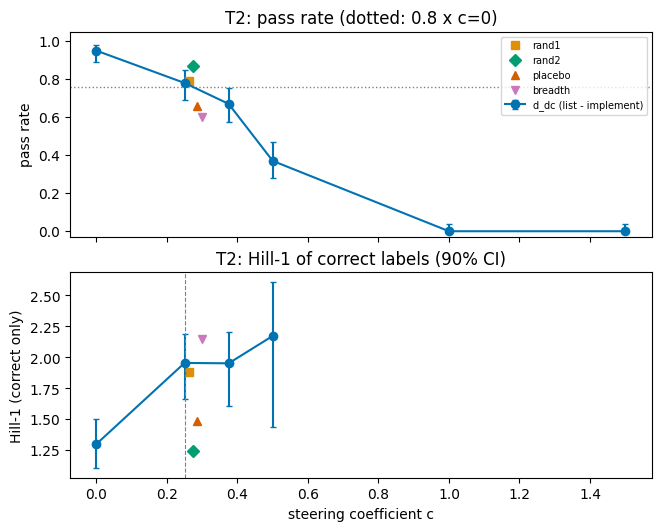

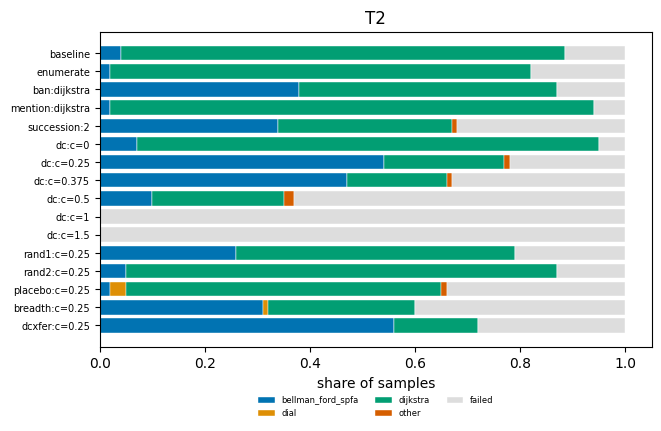

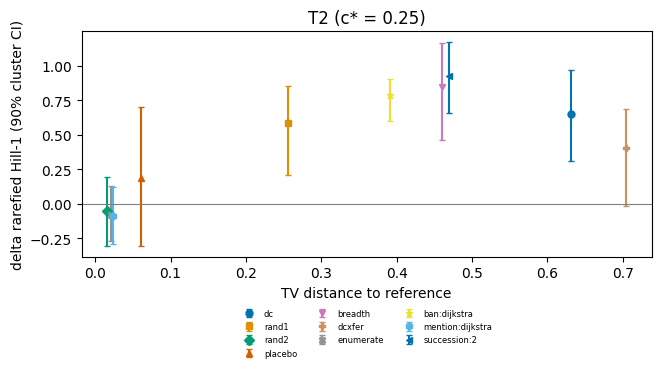

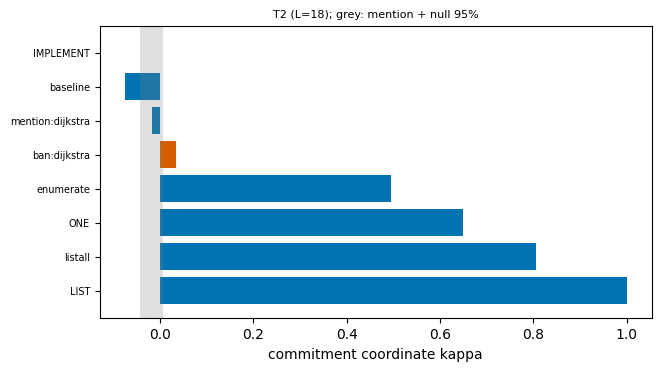

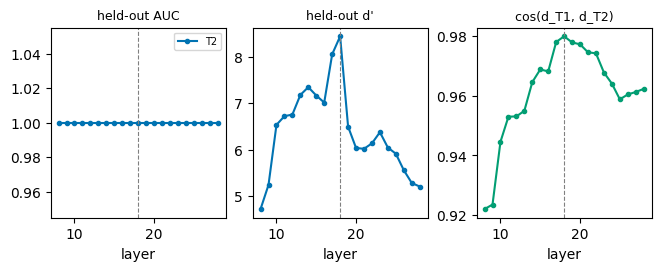

figures written


In [23]:
# ---- analysis/figures.py ----
# matplotlib.use("Agg")  # [notebook] not applied: the figures are shown inline
try:  # optional house style: point AII_DATA_FIG_GEN_SCRIPTS at the aii-data-fig-gen scripts directory
    import os
    sys.path.insert(0, os.environ["AII_DATA_FIG_GEN_SCRIPTS"])
    from chart_style import apply_house_style  # type: ignore
    apply_house_style()
except (KeyError, ImportError):
    plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42})

C = ["#0173B2", "#DE8F05", "#029E73", "#D55E00", "#CC78BC", "#CA9161", "#949494", "#ECE133", "#56B4E9"]


def save(fig, name: str) -> None:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{name}.pdf")
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=160)
    plt.show()  # [notebook] shown inline (the script calls plt.close(fig))


def fig1(summ: dict, cst: dict) -> None:
    L = cst["layer"]
    # [notebook] one column per task in TASKS (squeeze=False); the original is a fixed 2 x 2 grid for T1 and T2
    fig, axes = plt.subplots(2, len(TASKS), figsize=(6.5, 5.2), layout="constrained", sharex="col", squeeze=False)
    for j, t in enumerate(TASKS):
        cs = sorted(float(k) for k in cst[t]["pass_rates"])
        P, Plo, Phi, H, Hlo, Hhi, cx = [], [], [], [], [], [], []
        for c in cs:
            s = summ.get(f"{t}|steer:dc:c={c:g}:L={L}")
            if not s:
                continue
            cx.append(c)
            P.append(s["pass_rate"])
            Plo.append(s["pass_rate"] - s["wilson_ci"][0])
            Phi.append(s["wilson_ci"][1] - s["pass_rate"])
            h = s["hill_cc"]["hill1"]
            H.append(h if h is not None else float("nan"))
            ci = s.get("hill1_ci90_cluster") or [float("nan")] * 2
            Hlo.append((h - ci[0]) if h is not None else 0)
            Hhi.append((ci[1] - h) if h is not None else 0)
        ax = axes[0, j]
        ax.errorbar(cx, P, yerr=[Plo, Phi], marker="o", color=C[0], label="d_dc (list - implement)", capsize=2)
        ax.axhline(cst[t]["threshold"], ls=":", color="grey", lw=1)
        cstar = cst[t]["c_star"]
        for k, (nm, col, mk) in enumerate((("rand1", C[1], "s"), ("rand2", C[2], "D"), ("placebo", C[3], "^"),
                                           ("breadth", C[4], "v"))):
            s = summ.get(f"{t}|steer:{nm}:c={cstar:g}:L={L}")
            if s:
                ax.plot([cstar + 0.012 * (k + 1)], [s["pass_rate"]], mk, color=col, label=nm)
                h = s["hill_cc"]["hill1"]
                if h is not None:
                    axes[1, j].plot([cstar + 0.012 * (k + 1)], [h], mk, color=col)
        ax.set_title(f"{t}: pass rate (dotted: 0.8 x c=0)")
        ax.set_ylim(-0.03, 1.05)
        ax2 = axes[1, j]
        ax2.errorbar(cx, H, yerr=[Hlo, Hhi], marker="o", color=C[0], capsize=2)
        ax2.axvline(cstar, ls="--", color="grey", lw=0.8)
        ax2.set_title(f"{t}: Hill-1 of correct labels (90% CI)")
        ax2.set_xlabel("steering coefficient c")
        if j == 0:
            ax.set_ylabel("pass rate")
            ax2.set_ylabel("Hill-1 (correct only)")
    axes[0, -1].legend(fontsize=7, loc="upper right")  # [notebook] axes[0, 1] in the two-task grid
    save(fig, "fig1_dose_response")


def fig2(summ: dict, cst: dict, modes: dict) -> None:
    L = cst["layer"]
    fig, axes = plt.subplots(1, len(TASKS), figsize=(6.5, 4.2), layout="constrained", squeeze=False)  # [notebook]
    axes = axes[0]  # [notebook] one panel per task in TASKS
    for j, t in enumerate(TASKS):
        cs = cst[t]["c_star"]
        X = modes[t]["X"]
        arms = ["baseline", "enumerate", f"ban:{X}", f"mention:{X}", "succession:2"] + \
               [f"steer:dc:c={float(c):g}:L={L}" for c in sorted(float(k) for k in cst[t]["pass_rates"])] + \
               [f"steer:{n}:c={cs:g}:L={L}" for n in ("rand1", "rand2", "placebo", "breadth", "dcxfer")]
        arms = [a for a in arms if f"{t}|{a}" in summ]
        labs = sorted({k for a in arms for k in summ[f"{t}|{a}"]["label_counts_correct"]})
        ax = axes[j]
        left = [0.0] * len(arms)
        for i, lab in enumerate(labs + ["failed"]):
            vals = []
            for a in arms:
                s = summ[f"{t}|{a}"]
                vals.append((s["n"] - s["n_correct"]) / s["n"] if lab == "failed" else
                            s["label_counts_correct"].get(lab, 0) / s["n"])
            ax.barh(range(len(arms)), vals, left=left, color=("#DDDDDD" if lab == "failed" else C[i % len(C)]),
                    label=lab, edgecolor="white", lw=0.3)
            left = [l + v for l, v in zip(left, vals)]
        ax.set_yticks(range(len(arms)))
        ax.set_yticklabels([a.replace(f":L={L}", "").replace("steer:", "") for a in arms], fontsize=7)
        ax.invert_yaxis()
        ax.set_xlabel("share of samples")
        ax.set_title(t)
        ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
    save(fig, "fig2_label_distributions")


def fig3(buy: dict, cst: dict) -> None:
    fig, axes = plt.subplots(1, len(TASKS), figsize=(6.5, 3.6), layout="constrained", sharey=True, squeeze=False)
    axes = axes[0]  # [notebook] one panel per task in TASKS
    for j, t in enumerate(TASKS):
        ax = axes[j]
        cs = cst[t]["c_star"]
        quiet = []
        k_id = 0
        for k, v in buy[t].items():
            if k.startswith("_") or k in ("steer_vs_vllm_baseline", "enumerate@1024") or v.get("delta_hill_rarefied") is None:
                continue
            if k.startswith("steer:dc:") and f"c={cs:g}:" not in k:
                continue  # off-c* points of the dc curve are in fig1
            x, y = v.get("tv_to_reference"), v["delta_hill_rarefied"]
            ci = v.get("ci90_rarefied_cluster") or [y, y]
            name = k.replace("steer:", "").split(":L=")[0].replace(f":c={cs:g}", "")
            mk = "osD^vPX*h<>"[k_id % 11]
            ax.errorbar([x], [y], yerr=[[y - ci[0]], [ci[1] - y]], fmt=mk, color=C[k_id % len(C)], capsize=2, ms=5,
                        label=name)
            k_id += 1
            if abs(y) < 0.02 and x < 0.02:
                quiet.append(name)
        ax.axhline(0, color="grey", lw=0.8)
        ax.set_xlabel("TV distance to reference")
        ax.set_title(f"{t} (c* = {cs:g})")
        ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
    axes[0].set_ylabel("delta rarefied Hill-1 (90% cluster CI)")
    save(fig, "fig3_tv_vs_delta_hill")


def fig4(ct: dict, modes: dict) -> None:
    Ls = str(ct["layer_star"])
    fig, axes = plt.subplots(1, len(TASKS), figsize=(6.5, 3.6), layout="constrained", squeeze=False)  # [notebook]
    axes = axes[0]  # [notebook] one panel per task in TASKS
    for j, t in enumerate(TASKS):
        r = ct["per_task"][t][Ls]
        X = modes[t]["X"]
        keys = ["IMPLEMENT", "baseline", f"mention:{X}", f"ban:{X}", "enumerate", "ONE", "listall", "LIST"]
        vals = [r["kappa"][k] for k in keys]
        ax = axes[j]
        ax.barh(range(len(keys)), vals, color=[C[3] if k.startswith("ban") else C[0] for k in keys])
        b = r["ban"][X]
        lo, hi = b["null_band_95"]
        km = r["kappa"][f"mention:{X}"]
        ax.axvspan(km + lo, km + hi, color="grey", alpha=0.25, lw=0)
        ax.set_yticks(range(len(keys)))
        ax.set_yticklabels(keys, fontsize=7)
        ax.invert_yaxis()
        ax.set_xlabel("commitment coordinate kappa")
        ax.set_title(f"{t} (L={Ls}); grey: mention + null 95%", fontsize=8)
    save(fig, "fig4_commitment_kappa")


def fig5(sel: dict, diag: dict) -> None:
    ls = sorted(int(l) for l in sel["per_layer"])
    fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.6), layout="constrained")
    for j, t in enumerate(TASKS):
        axes[0].plot(ls, [sel["per_layer"][str(l)][t]["auc"] for l in ls], marker=".", color=C[j], label=t)
        axes[1].plot(ls, [sel["per_layer"][str(l)][t]["dprime"] for l in ls], marker=".", color=C[j], label=t)
    axes[2].plot(ls, [diag["per_layer"][str(l)]["cross_task_cos"] for l in ls], marker=".", color=C[2])
    for ax, ttl in zip(axes, ("held-out AUC", "held-out d'", "cos(d_T1, d_T2)")):
        ax.set_title(ttl, fontsize=9)
        ax.set_xlabel("layer")
        ax.axvline(sel["L_star"], ls="--", color="grey", lw=0.8)
    axes[0].legend(fontsize=7)
    save(fig, "fig5_layer_profiles")


# figures.py main()
summ = json.loads((RESULTS_DIR / "condition_summaries.json").read_text())  # written by the cells above
buy = json.loads((RESULTS_DIR / "buy_table.json").read_text())
cst = data["metadata"]["cstar"]                     # [notebook] the stored results/*.json below come from `data`
modes = data["metadata"]["modal_modes"]
ct = data["metadata"]["commitment_test"]
sel = data["metadata"]["layer_selection"]
diag = data["metadata"]["direction_diagnostics"]
for f, a in ((fig1, (summ, cst)), (fig2, (summ, cst, modes)), (fig3, (buy, cst)), (fig4, (ct, modes)),
             (fig5, (sel, diag))):
    try:
        f(*a)
    except Exception as e:  # noqa: BLE001 - one failing figure must not block the others
        print(f"figure {f.__name__} failed: {e!r}")
print("figures written")

## Results

**Recomputed vs stored.** The first table walks every result the `analyze` stage produced and compares it with the value the pipeline stored. Two kinds of quantity are reported separately:

* *exact* quantities, such as pass rates, counts, plug-in Hill numbers, TV distances, flips and the dose-response fits;
* *resampled* quantities, such as bootstrap CIs and rarefied estimates. These equal the stored values only at the original resampling sizes.

**Headline table.** The second table shows what each knob buys on T2.

**Same seed, different direction.** The heat maps use the common-random-number slots. Each row is the outcome the unsteered model produced in a slot (HF c = 0). Each column is what the *same prompt and seed* produced with a steering vector of strength c* = 0.25 added.

resampling sizes: NB = 2000, N_REP_POINT = 1000, N_REP_BOOT = 30  (original: 2000, 1000, 30)


,result,exact: max |recomputed - stored|,resampled: max |recomputed - stored|,other values that differ,e.g.
0,condition summaries,2.220446e-16,2.220446e-16,0,
1,engine check,0.000000e+00,0.000000e+00,0,
2,flips,0.000000e+00,0.000000e+00,0,
3,dose-response,3.064216e-14,6.572520e-14,0,
4,buy table,3.552714e-14,4.440892e-16,0,
5,PREDICT row,0.000000e+00,0.000000e+00,0,
6,move vs flatten,0.000000e+00,0.000000e+00,0,
7,screen verdict,0.000000e+00,0.000000e+00,0,


HF c=0 (steering reference): pass 0.950, correct programs {'dijkstra': 88, 'bellman_ford_spfa': 7}
vLLM baseline (prompt reference): pass 0.885, correct programs {'dijkstra': 169, 'bellman_ford_spfa': 8}


,knob,reference,pass,correct programs,ΔHill-1 rarefied [90% CI],stored
0,dc:c=0.25,HF c=0,0.78,"{'bellman_ford_spfa': 54, 'dijkstra': 23, 'oth...","+0.65 [0.31, 0.97]","+0.65 [0.31, 0.97]"
1,dc:c=0.375,HF c=0,0.67,"{'bellman_ford_spfa': 47, 'dijkstra': 19, 'oth...","+0.65 [0.29, 0.94]","+0.65 [0.29, 0.94]"
2,dc:c=0.5,HF c=0,0.37,"{'dijkstra': 25, 'bellman_ford_spfa': 10, 'oth...","+0.87 [0.09, 1.38]","+0.87 [0.09, 1.38]"
3,rand1:c=0.25,HF c=0,0.79,"{'dijkstra': 53, 'bellman_ford_spfa': 26}","+0.59 [0.21, 0.85]","+0.59 [0.21, 0.85]"
4,rand2:c=0.25,HF c=0,0.87,"{'dijkstra': 82, 'bellman_ford_spfa': 5}","-0.05 [-0.31, 0.20]","-0.05 [-0.31, 0.20]"
5,placebo:c=0.25,HF c=0,0.66,"{'dijkstra': 60, 'dial': 3, 'bellman_ford_spfa...","+0.19 [-0.30, 0.70]","+0.19 [-0.30, 0.70]"
6,breadth:c=0.25,HF c=0,0.60,"{'bellman_ford_spfa': 31, 'dijkstra': 28, 'dia...","+0.85 [0.46, 1.17]","+0.85 [0.46, 1.17]"
7,dcxfer:c=0.25,HF c=0,0.72,"{'bellman_ford_spfa': 28, 'dijkstra': 8}","+0.40 [-0.01, 0.69]","+0.40 [-0.01, 0.69]"
8,enumerate,vLLM baseline,0.82,"{'dijkstra': 80, 'bellman_ford_spfa': 2}","-0.08 [-0.27, 0.13]","-0.08 [-0.27, 0.13]"
9,ban:dijkstra,vLLM baseline,0.87,"{'dijkstra': 49, 'bellman_ford_spfa': 38}","+0.79 [0.60, 0.90]","+0.79 [0.60, 0.90]"


specificity  dc - rand1    +0.07 [-0.26, 0.39]   (stored +0.07 [-0.26, 0.39])
specificity  dc - rand2    +0.70 [0.38, 1.01]   (stored +0.70 [0.38, 1.01])
specificity  dc - placebo  +0.47 [0.01, 0.84]   (stored +0.47 [0.01, 0.84])
screen verdict: PARTIAL (stored: PARTIAL);  S_flat = True, S_specific = False, S_commit = de-commits


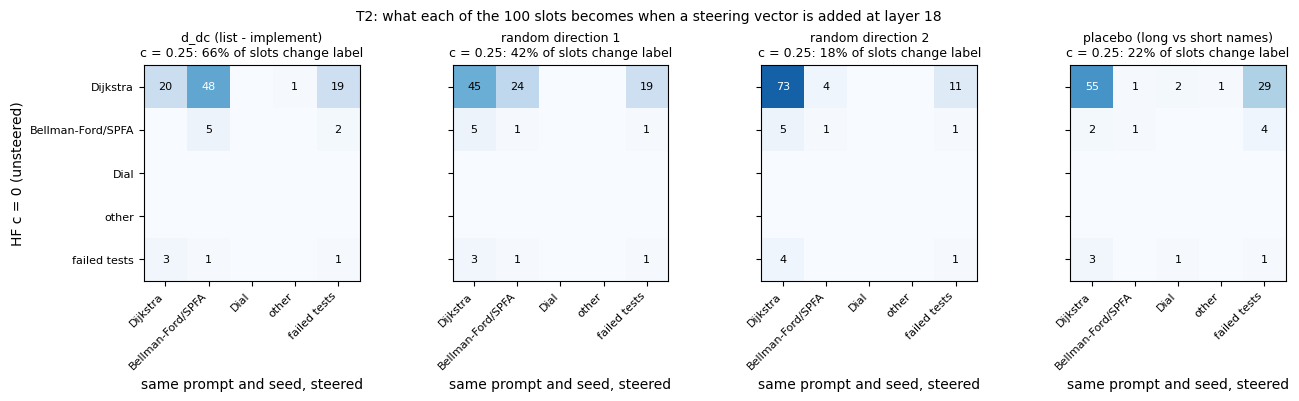

In [24]:
from IPython.display import display

# ---- [notebook] recomputed vs stored: every result of the analyze stage ----
st = data["metadata"]["stored_results"]
MC_KEYS = ("ci", "p_le_0", "rarefied", "efficiency", "point")  # quantities that depend on the resampling sizes


def compare_results(a, b, mc=False, out=None):
    """Walk two nested results; collect |a - b| of the numbers they share (exact vs resampled) and other differences."""
    out = {"exact": [0.0], "resampled": [0.0], "differ": []} if out is None else out
    if isinstance(a, dict) and isinstance(b, dict):
        out["differ"] += [f"missing key {k}" for k in sorted(a.keys() ^ b.keys())]
        for k in a.keys() & b.keys() - {"n_boot"}:  # n_boot is the number of resamples itself, not a result
            compare_results(a[k], b[k], mc or any(s in k for s in MC_KEYS), out)
    elif isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)) and len(a) == len(b):
        for x, y in zip(a, b):
            compare_results(x, y, mc, out)
    elif isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
        out["resampled" if mc else "exact"].append(0.0 if (math.isnan(a) and math.isnan(b)) else abs(a - b))
    elif a != b:
        out["differ"].append(f"{a!r} vs {b!r}"[:60])
    return out


blocks = {"condition summaries": (summ, st["conditions"]), "engine check": (eng, st["engine_check"]),
          "flips": (flips, st["flips"]), "dose-response": (dose, st["dose_response"]),
          "buy table": (buy, st["buy_table"]), "PREDICT row": (pr, st["predict_row"]),
          "move vs flatten": (mvf, st["move_vs_flatten"]),
          "screen verdict": ({"overall": verdict["overall"], "per_task": verdict["per_task"]}, st["screen_verdict"])}
cmp_rows = []
for name, (a, b) in blocks.items():
    o = compare_results(a, b)
    cmp_rows.append({"result": name, "exact: max |recomputed - stored|": max(o["exact"]),
                     "resampled: max |recomputed - stored|": max(o["resampled"]),
                     "other values that differ": len(o["differ"]), "e.g.": "; ".join(o["differ"][:2])})
print(f"resampling sizes: NB = {NB}, N_REP_POINT = {N_REP_POINT}, N_REP_BOOT = {N_REP_BOOT}  (original: 2000, 1000, 30)")
display(pd.DataFrame(cmp_rows))

# ---- [notebook] headline table: what each knob buys on T2 ----
t, cs, X = "T2", cst["T2"]["c_star"], modes["T2"]["X"]
for ref_name, k in (("HF c=0 (steering reference)", f"steer:dc:c=0:L={L}"), ("vLLM baseline (prompt reference)", "baseline")):
    print(f"{ref_name}: pass {S.pass_rate(by[(t, k)]):.3f}, correct programs "
          f"{dict(Counter(S.correct_labels(by[(t, k)])).most_common())}")
head = []
for k in ([f"steer:dc:c={c:g}:L={L}" for c in (0.25, 0.375, 0.5)]
          + [f"steer:{nm}:c={cs:g}:L={L}" for nm in ("rand1", "rand2", "placebo", "breadth", "dcxfer")]
          + ["enumerate", f"ban:{X}", f"mention:{X}", "succession:2"]):
    v, s = buy[t][k], st["buy_table"][t][k]
    head.append({"knob": k.replace("steer:", "").replace(f":L={L}", ""),
                 "reference": "HF c=0" if k.startswith("steer:") else "vLLM baseline", "pass": round(v["pass_rate"], 2),
                 "correct programs": dict(Counter(S.correct_labels(by[(t, k)])).most_common()),
                 "ΔHill-1 rarefied [90% CI]": f"{v['delta_hill_rarefied']:+.2f} {ci_str(v['ci90_rarefied_cluster'])}",
                 "stored": f"{s['delta_hill_rarefied']:+.2f} {ci_str(s['ci90_rarefied_cluster'])}"})
display(pd.DataFrame(head))
for nm, v in pt[t]["specificity"].items():
    sv = st["screen_verdict"]["per_task"][t]["specificity"][nm]
    print(f"specificity  dc - {nm:<8} {v['point']:+.2f} {ci_str(v['ci90'])}   (stored {sv['point']:+.2f} {ci_str(sv['ci90'])})")
print(f"screen verdict: {verdict['overall']} (stored: {st['screen_verdict']['overall']});  S_flat = {pt[t]['S_flat']}, "
      f"S_specific = {pt[t]['S_specific']}, S_commit = {pt[t]['S_commit']}")

# ---- [notebook] same prompt + seed, different steering direction: slot-by-slot transitions ----
c0rows = {(r["paraphrase_id"], r["sample_id"]): r for r in by[(t, f"steer:dc:c=0:L={L}")]}
arms = [("dc", "d_dc (list - implement)"), ("rand1", "random direction 1"), ("rand2", "random direction 2"),
        ("placebo", "placebo (long vs short names)")]


def outcome(r):
    return "failed" if not r["passed"] else (r["label"] if r["label"] in CATALOGUE[t] else "other")


seen = {outcome(r) for r in c0rows.values()} | {outcome(r) for nm, _ in arms for r in by[(t, f"steer:{nm}:c={cs:g}:L={L}")]}
cats = [c for c in CATALOGUE[t] + ["other"] if c in seen] + ["failed"]
names = {"dijkstra": "Dijkstra", "bellman_ford_spfa": "Bellman-Ford/SPFA", "bidirectional_dijkstra": "bidir. Dijkstra",
         "floyd_warshall": "Floyd-Warshall", "dial": "Dial", "other": "other", "failed": "failed tests"}
fig, axes = plt.subplots(1, len(arms), figsize=(3.4 * len(arms), 3.9), layout="constrained", sharey=True)
for ax, (nm, title) in zip(axes, arms):
    M = np.zeros((len(cats), len(cats)), dtype=int)
    for r in by[(t, f"steer:{nm}:c={cs:g}:L={L}")]:
        M[cats.index(outcome(c0rows[(r["paraphrase_id"], r["sample_id"])])), cats.index(outcome(r))] += 1
    ax.imshow(M, cmap="Blues", vmin=0, vmax=90)
    for i in range(len(cats)):
        for j in range(len(cats)):
            if M[i, j]:
                ax.text(j, i, str(M[i, j]), ha="center", va="center", fontsize=8,
                        color="white" if M[i, j] > 45 else "black")
    ax.set_xticks(range(len(cats)), [names[c] for c in cats], rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(cats)), [names[c] for c in cats], fontsize=8)
    f = flips[f"{t}|steer:{nm}:c={cs:g}:L={L}"]
    ax.set_title(f"{title}\nc = {cs:g}: {f['flip_rate']:.0%} of slots change label", fontsize=9)
    ax.set_xlabel("same prompt and seed, steered")
axes[0].set_ylabel("HF c = 0 (unsteered)")
fig.suptitle(f"{t}: what each of the {len(c0rows)} slots becomes when a steering vector is added at layer {L}", fontsize=10)
plt.show()

In [25]:
# ---- [notebook] one slot, same prompt and seed, without and with the d_dc vector ----
key = f"predict_{slug(f'steer:dc:c={cs:g}:L={L}')}"
moved = [e for e in examples if e["output"] == X and e["metadata_reference_passed"] and e[key] == "bellman_ford_spfa|pass"]
print(f"{len(moved)} of {len(examples)} slots go from a correct {X} program at c = 0 to a correct "
      f"Bellman-Ford/SPFA program at c = {cs:g}, with the same prompt and seed")
ex = moved[0]
print(f"\nslot: paraphrase {ex['metadata_paraphrase_id']}, sample {ex['metadata_sample_id']}; user prompt:\n{ex['input']}")
for cond in (f"steer:dc:c=0:L={L}", f"steer:dc:c={cs:g}:L={L}"):
    lab = ex["metadata_samples"][cond][0]
    print(f"\n{'=' * 24} {cond}: label {lab['label']}, hidden tests {'passed' if lab['passed'] else 'failed'}, "
          f"{lab['n_tokens']} tokens {'=' * 24}")
    print(ex["metadata_code"][cond].strip())

48 of 100 slots go from a correct dijkstra program at c = 0 to a correct Bellman-Ford/SPFA program at c = 0.25, with the same prompt and seed

slot: paraphrase 0, sample 0; user prompt:
Solve the following programming task.

Task: write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100); edges is a list of (u, v, w) tuples with integer weights 0 <= w <= 100; parallel edges, self-loops and cycles may occur. Return the length of a shortest path from s to t as an int, or -1 if t is unreachable from s (0 when s == t). Use only the Python standard library. Return only one ```python code block containing solve.

======================== steer:dc:c=0:L=18: label dijkstra, hidden tests passed, 218 tokens ========================
def solve(n, edges, s, t):
    from collections import deque

    # If start and target are the same, return 0
    if s == t:
        return 0

    # Build adjacency list
    adj = [[] for _ in range(n)]
    for u, v, w in edges

## What the numbers say

* **The model has a default.** Unprompted, Qwen3-8B writes Dijkstra for the weighted shortest path: 169 of the 177 correct vLLM baseline programs, and 88 of 95 at HF c = 0. On the grid task it writes BFS in every baseline, enumeration and steering sample; that task is not in this demo's data.
* **De-commitment steering moves the default, but not specifically.** At c* = 0.25, d_dc turns most correct programs into Bellman-Ford/SPFA, 54 against 23 Dijkstra. That is +0.65 rarefied Hill-1, at a 17-point pass-rate cost. A random direction of the same norm at the same layer (rand1) moves Dijkstra slots the same way. In the heat maps, rand1 turns 24 of the 88 Dijkstra slots into Bellman-Ford where d_dc turns 48, yet its diversity gain is almost as large (+0.59). dc − rand1 = +0.07, with a 90 % CI that spans 0, so S_specific fails. d_dc does beat the second random direction and the variable-name placebo.
* **Prompting.** "List 10 approaches, then implement one" changes nothing (ΔHill −0.08). Banning Dijkstra buys more diversity (+0.79) at a 1.5-point pass cost, although 49 of the 87 correct "banned" programs still use Dijkstra.
* **Forecasts.** On T2 the de-committed forecast predicted the ban outcome (Bellman-Ford) better than the frequency forecasts. It was committed by hash before any ban sample existed, but it rests on one informative event.

## Running at full scale

* **Analysis at the original sizes.** Set `NB = 2000`, `N_REP_POINT = 1000`, `N_REP_BOOT = 30` and `N_MC = 20000` in the config cell. These are `analyze.py`'s defaults, and with them the recomputed T2 intervals equal the stored ones.
* **The whole experiment.**
  1. Clone the artifact folder.
  2. Create its environment: `uv venv .venv --python 3.12 && uv pip install --python .venv/bin/python -r requirements.txt`.
  3. Download `Qwen/Qwen3-8B` (`hf download Qwen/Qwen3-8B`, about 16 GB).
  4. Put this notebook in that folder, set `RUN_STAGE_SCRIPTS = True` and run it on a GPU with at least 20 GB. That takes about 2.1 GPU-hours plus $0.06 of judge calls through OpenRouter (`OPENROUTER_API_KEY`). Running `.venv/bin/python method.py` does the same thing.